# DS3 benchmarking profile

## Overview
DS3's KPIs (T1, T2, fRB, fCX, fRO) are our only per-run read on how good the device is after calibration, so before any temporal work we need to know which values to trust, what the gating hides, and whether each metric moves from run to run by more than its own noise ([Phase 01, B4](../../docs/phases/01_eda.md#b4-ds3-benchmarking)). We profile 3d's `kpi_supplemented` - DS3's table plus the payload fits behind it. The DS3 side is in [datasheet 3](../../docs/datasheets/03_benchmarking_files.md).

**Question.** Which KPI values can we keep, is what's missing missing at random, and does each metric move beyond its noise?

**Method.** We gate every era the same way and set up the strata (section 1), then look at what's censored or absent (section 2) and at the kept values and fit quality (section 3). Section 4 is the core: each metric's noise floor and signal ratio, written to `noise_floor.parquet`. Section 5 screens for level shifts, and section 6 collects what Phases C and D need.


In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import decode, periods
from qpu_drift.derived.noise import write_noise_rows
from qpu_drift.derived.run_map import load_run_map
from qpu_drift.derived.supplement import PAYLOAD_FITS, PAYLOAD_LINKS, read_fit
from qpu_drift.paths import DERIVED, RAW, REPO_ROOT
from qpu_drift.sources.benchmarking.clean import gate, r2_pregated
from qpu_drift.sources.benchmarking.constants import PHYS_RANGE, R2_GATE
from qpu_drift.sources.benchmarking.load import DERIVED_DIR, KPI_SUPPLEMENTED_PATH, load_kpi_l2, load_runs_l2
from qpu_drift.sources.hardware_models import load_values

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250, "display.max_colwidth", 80)
FIG = REPO_ROOT / "docs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)
FILES = {"links": DERIVED_DIR / PAYLOAD_LINKS,
         "fits": DERIVED_DIR / PAYLOAD_FITS,
         "config": DERIVED / "measurements" / "config_settings.parquet"}

runs = load_runs_l2()
kpi = load_kpi_l2(path=KPI_SUPPLEMENTED_PATH)
links = pd.read_parquet(FILES["links"])
fits = pd.read_parquet(FILES["fits"])
cfg = pd.read_parquet(FILES["config"])
print(f"{len(runs)} DS3 runs {runs['created_at'].min():%Y-%m-%d} to {runs['created_at'].max():%Y-%m-%d}; {len(kpi)} KPI rows;",
      "runs per gating_regime:", runs["gating_regime"].value_counts().to_dict())

METRICS = ["T1", "T2", "fRB", "fCX", "fRO"]
UNIT = {"T1": "s", "T2": "s", "fRB": "fidelity", "fCX": "fidelity", "fRO": "fidelity"}
MIN_N = 20
RB_JUNE = pd.Timestamp("2026-06-01")  # 3a section 3: RB durations step in 2026-06
SEG_DATE = {0: "0 (start)"} | {i: f"{i} ({b.at:%Y-%m-%d})" for i, b in enumerate(periods.BREAKS, 1)}
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]

def rsd(s: pd.Series) -> float:
    """Robust sd: 1.4826 x the median absolute deviation."""
    return 1.4826 * (s - s.median()).abs().median()

655 DS3 runs 2024-05-24 to 2026-09-14; 104800 KPI rows; runs per gating_regime: {'era3_postproc': 317, 'era1_filter': 223, 'era0_ungated': 75, 'era2_ungated': 40}


## 1. Gate and strata

First every KPI row gets one time, its strata and its flags. A run's time $t$ is its `measured_at` (the `output_info` run start), else `created_at`. The stratum is the `BREAKS` segment of $t$, with `SETTLING` on its own, and fRB and fCX split off again from 2026-06-01, where the RB durations step (3a section 3). The gating eras are era 0 to 2024-08-17, era 1 from 2024-10-15 to 2025-07-07, era 2 to 2025-08-22 and era 3 after. An fCX row is `f01_flag`ged when either of its qubits is.

Then the gate - one rule for every era. We run `gate(metric, value, r2, pregated)` (`R2_GATE`, `PHYS_RANGE`) on DS3's value and r2, each filled from the payload where DS3 has none. An in-range value with no r2 is `ok` only where Level 2 counts it as pregated (DS3's own `ok`), else `no_r2`: served, but not judgeable. As a build check we recompute `pregated` from the Level-2 rule (`clean.r2_pregated`) and ask whether `gate` on DS3's own value and r2 gives back `value_status`. Kept rows are `ok` and outside `INCIDENTS`, the f01 flags and retired couplings, and they're all that sections 3 to 6 use.

Last, the fCX lengths list: the payload's `rb_lengths` (14 lengths short, 17 long), else predicted from the coupling's previous value and r2 with the benchmarking routine's rule (`benchmarking.py` lines 246-250 and 270-273). The routine scores each coupling

$$q = \begin{cases} \lfloor 100F \rfloor & r^2 > 0.8 \\ 50 & \text{otherwise} \end{cases}$$

and runs the short list when $q < 92$. A previous value with no r2 (era 0, or the 2025-11-08 record) has no fit quality to read, so there we take $q = \lfloor 100F \rfloor$.


In [2]:
k = kpi.merge(runs[["created_at", "gating_regime"]], on="created_at", how="left")
k["run"] = k["created_at"].rank(method="dense").astype(int) - 1
run_t = k.groupby("run")["measured_at"].min()
k["t"] = k["run"].map(run_t).fillna(k["created_at"])  # one time per run: its output_info start, else created_at
lag_h = (k["created_at"] - k["measured_at"]).dt.total_seconds() / 3600
print(f"t = the run's measured_at (output_info run start), else created_at: {run_t.isna().sum()} of {len(run_t)} runs fall back;",
      f"created_at - measured_at median {lag_h.median():.2f} h, max {lag_h.max():.2f} h")
qa = k["element"].str.split("-").str[0].astype(int)
qb = k["element"].str.split("-").str[1].astype(float).fillna(-1).astype(int)
k["incident"] = periods.within(k["t"], *[i.period for i in periods.INCIDENTS])
k["f01_flag"] = periods.f01_flagged(k["t"], qa) | periods.f01_flagged(k["t"], qb)  # 2q: control or target
k["settling"] = periods.within(k["t"], *periods.SETTLING)
k["in_study"] = periods.within(k["t"], periods.STUDY_PERIODS["ds1_ds3"])
k["segment"] = periods.segment(k["t"])
k["stratum"] = np.where(k["settling"], "settling", k["segment"].map(SEG_DATE))
june = k["metric"].isin(["fRB", "fCX"]) & (k["t"] >= RB_JUNE) & ~k["settling"]
k.loc[june, "stratum"] = k.loc[june, "stratum"] + " RB from 2026-06"
print("runs per stratum (RB metrics split at 2026-06):")
display(k.groupby("stratum")["run"].nunique().rename("runs").to_frame().T)
print("3d in_incident against INCIDENTS on t (rows):")
display(pd.crosstab(k["in_incident"], k["incident"]))
print("f01_flag rows outside INCIDENTS, per metric:", k[k["f01_flag"] & ~k["incident"]].groupby("metric").size().to_dict())

# coupling set: the fCX elements DS3 lists in each run
cset = k[k["metric"] == "fCX"].groupby("run")["element"].agg(frozenset)
chg = cset[cset != cset.shift()]
print(f"{len(chg)} coupling sets over {len(cset)} runs; changes (first run of each set):")
display(pd.DataFrame([{"first_run_t": k.loc[k["run"] == r, "t"].min(), "couplings": len(s),
                       "joined": sorted(s - p) if p is not None else [], "left": sorted(p - s) if p is not None else []}
                      for (r, s), p in zip(chg.items(), [None, *chg.iloc[:-1]])]))

# one gate for every era, on the DS3 value and r2, filled from the payload where DS3 has none. An in-range value with
# no r2 is ok only if pregated: Level 2 counts an era-1 value off the output_info cache as pregated (clean.r2_pregated),
# so a DS3 ok with no r2 stays pregated here, as in analysis.series.kpi_rows
k["value_u"] = k["value"].fillna(k["payload_value"])
k["r2_u"] = k["r2"].fillna(k["payload_r2"])
k["error_u"] = k["error"].fillna(k["payload_error"])
k["source_u"] = np.select([k["value"].notna(), k["payload_value"].notna()], ["ds3", "payload"], "none")
k["status_u"] = pd.Series([gate(m, v, r, pregated=s == "ok")
                           for m, v, r, s in zip(k["metric"], k["value_u"], k["r2_u"], k["value_status"])], index=k.index)
pregated_l2 = pd.Series([r2_pregated(t, m) for t, m in zip(k["created_at"], k["metric"])], index=k.index) & k["measured_at"].isna()
print("build check: gate(metric, value, r2, pregated) on DS3's own value and r2, pregated by the Level-2 rule (era 1 off the",
      "output_info cache, crash cohort out), equals value_status wherever it returns a status:",
      bool((pd.Series([gate(m, v, r, pregated=pg) for m, v, r, pg in zip(k["metric"], k["value"], k["r2"], pregated_l2)], index=k.index)
            .pipe(lambda s: (s == k["value_status"]) | s.isna())).all()))
k["status_u"] = k["status_u"].fillna(k["value_status"])  # no value from either source: DS3's absent status
print(f"B4 status (gate on value, else payload_value, with r2, else payload_r2; R2_GATE {R2_GATE}, PHYS_RANGE {PHYS_RANGE})",
      "against DS3 value_status, per metric:")
display(pd.crosstab([k["metric"], k["value_status"]], k["status_u"]))
print("rows by value source and whether the B4 status is ok:")
display(pd.crosstab(k["metric"], [k["source_u"], k["status_u"] == "ok"]))

# what the payload fill adds: DS3 no_result rows that the payload makes ok
fill = k[(k["value_status"] == "no_result") & (k["status_u"] == "ok")]
print("DS3 no_result -> B4 ok rows per metric and era:", fill.groupby(["metric", "gating_regime"]).size().to_dict())
print("  per month:", fill.groupby([fill["metric"], fill["t"].dt.to_period("M")]).size().unstack(0).fillna(0).astype(int).to_dict("index"))
t1_run = k[k["metric"] == "T1"].groupby("run").agg(t=("t", "min"), ds3_values=("value", "count"), filled=("source_u", lambda s: (s == "payload").sum()))
gap = t1_run[(t1_run["ds3_values"] <= 2) & (t1_run["filled"] > 0)]
print(f"  runs where DS3 serves at most 2 T1 values and the payload fills others: {len(gap)},",
      f"{gap['t'].min():%Y-%m-%d %H:%M} to {gap['t'].max():%Y-%m-%d %H:%M}; DS3 T1 qubits in them:",
      k[k["run"].isin(gap.index) & (k["metric"] == "T1") & k["value"].notna()].groupby("run")["element"]
      .agg(lambda s: ",".join(sorted(s))).value_counts().to_dict())
tt_ok = k[k["metric"].isin(["T1", "T2"]) & (k["value_status"] == "ok")]
print("  relative fit error, median: filled rows", round(float((fill["error_u"] / fill["value_u"]).median()), 3),
      "; DS3 ok T1 and T2 rows", round(float((tt_ok["error"] / tt_ok["value"]).median()), 3),
      "; filled rows with a payload error:", round(float(fill["error_u"].notna().mean()), 3))

# values DS3 serves with no R² that no producer pregated (no_r2): the payload r2 re-gates the ones it covers
e1 = k[(k["gating_regime"] == "era1_filter") & (k["value_status"] == "ok") & (k["metric"] != "fRO")]
print(f"era-1 DS3 ok rows (T1, T2, fRB, fCX): {len(e1)}, with no DS3 r2: {int(e1['r2'].isna().sum())}")
nr = k[k["value_status"] == "no_r2"]
print(f"DS3 no_r2 rows: {len(nr)}, {nr['t'].min():%Y-%m-%d} to {nr['t'].max():%Y-%m-%d}; with a payload r2: {int(nr['payload_r2'].notna().sum())};",
      "B4 status per era, metric and month:")
display(pd.crosstab([nr["gating_regime"], nr["metric"], nr["t"].dt.to_period("M")], nr["status_u"]))

# a no_r2 value was served but can't be judged: its own class, neither kept, censored nor absent
k["cls"] = np.select([k["status_u"] == "ok", k["status_u"].isin(["low_r2", "out_of_range", "no_fit"]), k["status_u"] == "no_r2"],
                     ["ok", "censored", "no_r2"], "absent")
k["use"] = (k["cls"] == "ok") & ~k["incident"] & ~k["f01_flag"] & ~k["coupling_retired"]
print("rows per metric: B4 ok, and kept for noise and stationarity (outside INCIDENTS, f01 flags and retired couplings):")
display(k.groupby("metric").agg(rows=("run", "size"), ok=("cls", lambda s: (s == "ok").sum()), kept=("use", "sum"),
                                kept_settling=("settling", lambda s: (s & k.loc[s.index, "use"]).sum()),
                                kept_in_study=("in_study", lambda s: (s & k.loc[s.index, "use"]).sum())))

# fCX list: short when the coupling's quality is below 92, quality = int(100 x fidelity) if the fit quality > 0.8,
# else 50 (benchmarking.py 246-250, 270-273), set by the previous run's fit. A previous value with no r2 (era 0, which
# had no gate, and the 2025-11-08 record) has no fit quality to read, so its quality is taken as int(100 x fidelity).
fc = k[k["metric"] == "fCX"].sort_values(["element", "run"])
last = fc[["value_u", "r2_u"]].where(fc["value_u"].notna()).groupby(fc["element"]).shift().groupby(fc["element"]).ffill()
quality = np.where(last["r2_u"].isna() | (last["r2_u"] > 0.8), np.floor(100 * last["value_u"]), 50)
print(f"fCX rows whose previous value has no r2 (quality from the value alone): {int((last['value_u'].notna() & last['r2_u'].isna()).sum())}")
k.loc[fc.index, "list_pred"] = np.where(last["value_u"].isna(), None, np.where(quality < 92, "short", "long"))
n_len = k["rb_lengths"].dropna().map(lambda s: len(json.loads(s)))
print("fCX rb_lengths list length:", n_len[k["metric"] == "fCX"].value_counts().to_dict())
k["list"] = n_len.map(lambda n: "short" if n <= 14 else "long").reindex(k.index).where(k["metric"] == "fCX")
print("fCX payload list against the list predicted from the previous run's value and r2 (all statuses):")
display(pd.crosstab(k.loc[k["metric"] == "fCX", "list"].fillna("no payload"), k.loc[k["metric"] == "fCX", "list_pred"].fillna("no previous value")))
k["list_b4"] = k["list"].fillna(k["list_pred"]).where(k["metric"] == "fCX")  # payload list, else the predicted one


t = the run's measured_at (output_info run start), else created_at: 92 of 655 runs fall back; created_at - measured_at median 2.97 h, max 6.71 h


runs per stratum (RB metrics split at 2026-06):


stratum,0 (start),1 (2024-05-28),11 (2026-03-24),12 (2026-05-21),13 (2026-05-25),13 (2026-05-25) RB from 2026-06,2 (2024-09-18),3 (2025-02-12),4 (2025-02-17),6 (2025-03-20),7 (2025-03-28),8 (2025-07-07),9 (2025-08-22),settling
runs,4,71,43,1,84,78,99,5,15,7,97,40,181,8


3d in_incident against INCIDENTS on t (rows):


incident,False,True
in_incident,,
False,104640,0
True,0,160


...

rows per metric: B4 ok, and kept for noise and stationarity (outside INCIDENTS, f01 flags and retired couplings):


,rows,ok,kept,kept_settling,kept_in_study
metric,,,,,
T1,20960,16902,16902,218,16496
T2,20960,13714,13714,184,13354
fCX,20960,15984,15984,205,15680
fRB,20960,15578,15578,210,15222
fRO,20960,20783,20741,256,17923


fCX rows whose previous value has no r2 (quality from the value alone): 2399
fCX rb_lengths list length: {17: 2065, 14: 1509}


fCX payload list against the list predicted from the previous run's value and r2 (all statuses):


list_pred,long,no previous value,short
list,,,
long,2059,1,5
no payload,12829,34,4523
short,34,0,1475


**Results.**

- `t` falls back to `created_at` on 92 of 655 runs. Elsewhere `created_at` trails `measured_at` by a median 2.97 h (max 6.71 h).
- `in_incident` agrees with `INCIDENTS` on every row. Outside `INCIDENTS`, `f01_flag` hits 29 rows per 1q metric and 58 fCX.
- DS3 lists three coupling sets of 32: on 2024-05-28 1-2 and 17-25 replace 2-1 and 25-17, and on 2026-03-24 10-1 and 2-1 replace 1-10 and 1-2.
- The build check holds - `gate` gives back `value_status` wherever it returns a status.
- The payload fill turns T1 `no_result` rows into 2,333 `ok`, 60 `low_r2` and 95 `out_of_range`, and T2 into 1,777, 455 and 256. No DS3 `ok` row changes, and fCX, fRB and fRO come entirely from DS3.
- The added `ok` rows sit in 2025-04 to 07 and 2025-11. That's a DS3 serving gap: in 84 runs (2025-04-11 to 2025-11-08) DS3 serves T1 on at most 2 qubits (Q1 and Q2 in 82) and the payload fills the rest. Their median relative fit error (0.094) matches DS3's own `ok` rows (0.096).
- DS3 serves 8,777 `no_r2` rows, 2024-05-24 to 2025-11-08. All of era 0 stays `no_r2` (T1 2,229, T2 1,969, fCX 2,066, fRB 2,158). The payload r2 re-gates 326: era-1 T1 and T2 in 2025-04 to 07 (T1 155 `ok`; T2 101 `ok` and 63 `low_r2`) and 7 fCX in 2025-11 (5 `ok`, 2 `low_r2`).
- Kept rows: T1 16,902, T2 13,714, fCX 15,984, fRB 15,578, fRO 20,741.
- The predicted fCX list matches the payload's on 2,059 long and 1,475 short rows and misses on 5 and 34. Without a payload, 12,829 rows are predicted long, 4,523 short, and 34 have no previous value.


## 2. Coverage and missingness

Now the rows that didn't make it. We keep three kinds apart: censored fits (`low_r2`, `out_of_range`, `no_fit`), absent results (no value from DS3 or the payload), and `no_r2` values, which are neither. Per entity the censored share is

$$c = \frac{n_\text{censored}}{n_\text{ok} + n_\text{censored}}$$

outside `INCIDENTS`, the f01 flags and retired couplings. We leave out era-0 fits (T1, T2, fRB, fCX) - with no r2 there only `out_of_range` can be judged, so their share would mean nothing. `unresolved` rows (no `output_info` file, no payload) might be values the producer gated out, so we bound the share with them as absent (lower) and as censored (upper). We also check absences by qubit group and by window.


In [3]:
out = ~k["incident"]
print("B4 status share per metric and gating era, outside INCIDENTS (rows):")
tab = pd.crosstab([k.loc[out, "metric"], k.loc[out, "gating_regime"]], k.loc[out, "status_u"], normalize="index")
display(tab.round(4).assign(rows=k[out].groupby(["metric", "gating_regime"]).size()))

# censored share of attempted fits (ok + censored), per entity, outside INCIDENTS, f01 flags and retired couplings.
# Era 0 serves no R² for the fits (section 1), so ok is undecidable there and its fits are left out
era0_fit = (k["gating_regime"] == "era0_ungated") & (k["metric"] != "fRO")
base = k[~k["incident"] & ~k["f01_flag"] & ~k["coupling_retired"] & ~era0_fit]
att = base[base["cls"].isin(["ok", "censored"])]
cens = att.groupby(["metric", "element"])["cls"].agg(lambda s: (s == "censored").mean()).rename("censored_share")
att_ds3 = base[base["value_status"].isin(["ok", "low_r2", "out_of_range", "no_fit"])]
cens_ds3 = (att_ds3["value_status"] != "ok").groupby([att_ds3["metric"], att_ds3["element"]]).mean().rename("ds3_value_status_share")
print("censored share per entity (censored = low_r2, out_of_range or no_fit; share of ok + censored; era-0 fits left out), B4 status:")
display(cens.groupby("metric").agg(entities="size", median="median", max="max",
                                   over_10pct=lambda s: (s > 0.10).sum(), share_over_10pct=lambda s: (s > 0.10).mean()).round(4))
print("entities over 10%, largest first (with the same share from DS3's value_status):")
display(pd.concat([cens, cens_ds3], axis=1)[cens > 0.10].sort_values("censored_share", ascending=False).round(4))
print("censored share per era (B4 status), per metric: median and max over entities")
cens_e = att.groupby(["metric", "gating_regime", "element"])["cls"].agg(lambda s: (s == "censored").mean())
display(cens_e.groupby(["metric", "gating_regime"]).agg(["median", "max", lambda s: (s > 0.10).mean()])
        .rename(columns={"<lambda_0>": "share_over_10pct"}).round(4))

# censored-share bounds: unresolved rows (no matched output_info file, no payload) may be values the producer gated out.
# Lower bound counts them as absent (above); upper bound counts them as censored.
att_hi = base[base["cls"].isin(["ok", "censored"]) | (base["status_u"] == "unresolved")]
cens_e_hi = att_hi.groupby(["metric", "gating_regime", "element"])["cls"].agg(lambda s: (s != "ok").mean())
print("censored-share bounds per metric and era: unresolved share of rows, and median and share over 10% of the per-entity",
      "censored share with unresolved rows as absent (lower) or censored (upper):")
display(pd.DataFrame({
    "unresolved_share": base.groupby(["metric", "gating_regime"])["status_u"].agg(lambda s: (s == "unresolved").mean()),
    "median_lower": cens_e.groupby(["metric", "gating_regime"]).median(),
    "median_upper": cens_e_hi.groupby(["metric", "gating_regime"]).median(),
    "over_10pct_lower": cens_e.groupby(["metric", "gating_regime"]).agg(lambda s: (s > 0.10).mean()),
    "over_10pct_upper": cens_e_hi.groupby(["metric", "gating_regime"]).agg(lambda s: (s > 0.10).mean())}).round(4))

# absent results by qubit group: T1 and T2 payloads are per group (payload_links key), RB1q per group (payload name)
gl = links.loc[links["key"].str.startswith("group", na=False), ["metric", "result_id", "key"]]
gm = fits[["metric", "result_id", "element"]].astype({"element": str}).merge(gl, on=["metric", "result_id"])
keys = gm.groupby(["metric", "element"])["key"].nunique()
print("T1 / T2 payload targets with a group pointer:", gm.groupby("metric").size().to_dict(),
      "; qubit-metrics in more than one group:", int((keys > 1).sum()))
grp = gm[gm["metric"] == "T1"].groupby("element")["key"].agg(lambda s: s.mode().iloc[0])
rbl = links[(links["metric"] == "fRB") & links["path"].notna()]
rbg = rbl["path"].str.extract(r"rb1q_(group\d)")[0].groupby(rbl["element"]).agg(lambda s: s.mode().iloc[0])
print("T2 group by qubit equals T1:", grp.equals(gm[gm["metric"] == "T2"].groupby("element")["key"].agg(lambda s: s.mode().iloc[0])),
      "; RB1q group (payload name) equals T1:", rbg.sort_index().equals(grp.sort_index()),
      "; qubits per group:", grp.value_counts().to_dict(), "; qubits with no group:", sorted(set(k["element"][k["metric"] == "T1"]) - set(grp.index)))
k["group"] = k["element"].map(grp).where(k["metric"].isin(["T1", "T2", "fRB"]))
gsize = grp.value_counts()
ab = (k[k["metric"].isin(["T1", "T2", "fRB"])].groupby(["metric", "run", "group"])
      .agg(absent=("cls", lambda s: (s == "absent").sum()), incident=("incident", "any"), settling=("settling", "any"), t=("t", "min")))
ab["kind"] = np.select([ab["absent"] == 0, ab["absent"] == ab.index.get_level_values("group").map(gsize)], ["none", "whole group"], "partial")
print("run-groups by absent qubits (qubit groups of", gsize.to_dict(), "), per metric and INCIDENTS:")
display(pd.crosstab([ab.index.get_level_values("metric"), ab["incident"]], ab["kind"]))
part = ab[(ab["kind"] == "partial") & ~ab["incident"]]
print("partial run-groups outside INCIDENTS, absent qubits per run-group:",
      part.groupby(level="metric")["absent"].describe()[["count", "50%", "max"]].to_dict("index"))
whole = ab[(ab["kind"] == "whole group") & ~ab["incident"]].reset_index()
print("whole-group absences outside INCIDENTS: run-groups per metric", whole.groupby("metric").size().to_dict(),
      "; T1 and T2 absent together in", len(set(map(tuple, whole.loc[whole["metric"] == "T1", ["run", "group"]].values))
                                            & set(map(tuple, whole.loc[whole["metric"] == "T2", ["run", "group"]].values))), "run-groups")
print("whole-group absences outside INCIDENTS per month:")
display(pd.crosstab(whole["t"].dt.to_period("M"), whole["metric"]))

# where do absent, censored and no_r2 rows fall
win = np.select([k["incident"], k["f01_flag"], k["settling"], k["coupling_retired"]],
                ["INCIDENTS", "F01_FLAGS (not incident)", "SETTLING", "coupling_retired"], "other")
print("share of rows absent, censored and no_r2 per metric and window:")
display(k.assign(window=win).groupby(["metric", "window"]).agg(
    rows=("cls", "size"), absent=("cls", lambda s: (s == "absent").mean()), censored=("cls", lambda s: (s == "censored").mean()),
    no_r2=("cls", lambda s: (s == "no_r2").mean())).round(4))


B4 status share per metric and gating era, outside INCIDENTS (rows):


status_u              low_r2  no_fit   no_r2  no_result      ok  out_of_range  unresolved   rows
metric gating_regime                                                                            
T1     era0_ungated   0.0000  0.0000  0.9288     0.0000  0.0000        0.0142      0.0571   2400
       era1_filter    0.0441  0.0000  0.0000     0.0048  0.9218        0.0293      0.0000   7136
       era2_ungated   0.0234  0.0000  0.0000     0.0000  0.9328        0.0438      0.0000   1280
       era3_postproc  0.0558  0.0000  0.0000     0.0032  0.9029        0.0352      0.0030  10112
T2     era0_ungated   0.0000  0.0000  0.8204     0.0000  0.0000        0.0142      0.1654   2400
       era1_filter    0.1442  0.0000  0.0000     0.0048  0.7628        0.0883      0.0000   7136
       era2_ungated   0.2016  0.0000  0.0000     0.0000  0.7008        0.0977      0.0000   1280
       era3_postproc  0.1934  0.0000  0.0000     0.0032  0.7292        0.0712      0.0030  10112
fCX    era0_ungated   0.0000  0.0000  0.8608     0.0079  0.0000        0.0150      0.1162   2400
       era1_filter    0.0544  0.0014  0.0000     0.0277  0.9165        0.0000      0.0000   7136
       era2_ungated   0.0680  0.0000  0.0000     0.0281  0.9039        0.0000      0.0000   1280
       era3_postproc  0.1084  0.0008  0.0029     0.0583  0.8195        0.0002      0.0099  10112
fRB    era0_ungated   0.0000  0.0000  0.8992     0.0000  0.0000        0.0004      0.1004   2400
       era1_filter    0.0914  0.0000  0.0000     0.0338  0.8749        0.0000      0.0000   7136
       era2_ungated   0.1148  0.0000  0.0000     0.1031  0.7820        0.0000      0.0000   1280
       era3_postproc  0.1110  0.0000  0.0000     0.0573  0.8242        0.0000      0.0076  10112
fRO    era0_ungated   0.0000  0.0000  0.0000     0.0000  0.9733        0.0000      0.0267   2400
       era1_filter    0.0000  0.0000  0.0000     0.0048  0.9952        0.0000      0.0000   7136
       era2_ungated   0.0000  0.0000  0.0000     0.0000  1.0000        0.0000      0.0000   1280
       era3_postproc  0.0000  0.0000  0.0000     0.0032  0.9939        0.0000      0.0030  10112

censored share per entity (censored = low_r2, out_of_range or no_fit; share of ok + censored; era-0 fits left out), B4 status:


,entities,median,max,over_10pct,share_over_10pct
metric,,,,,
T1,32,0.0417,0.5174,10,0.3125
T2,32,0.1224,0.8733,18,0.5625
fCX,34,0.0362,0.7245,8,0.2353
fRB,32,0.0372,0.5572,8,0.2500
fRO,32,0.0000,0.0000,0,0.0000


entities over 10%, largest first (with the same share from DS3's value_status):


...

kind            none  partial  whole group
row_0 incident                            
T1    False     1271       24           13
      True         1        0            1
T2    False     1209       89           10
      True         1        0            1
fRB   False     1163       74           71
      True         1        0            1

partial run-groups outside INCIDENTS, absent qubits per run-group: {'T1': {'count': 24.0, '50%': 1.0, 'max': 2.0}, 'T2': {'count': 89.0, '50%': 4.0, 'max': 7.0}, 'fRB': {'count': 74.0, '50%': 1.0, 'max': 16.0}}
whole-group absences outside INCIDENTS: run-groups per metric {'T1': 13, 'T2': 10, 'fRB': 71} ; T1 and T2 absent together in 10 run-groups
whole-group absences outside INCIDENTS per month:


metric,T1,T2,fRB
t,,,
2024-06,5,2,6
2024-08,2,2,2
2024-10,0,0,3
2024-11,0,0,1
2025-01,0,0,1
2025-03,0,0,1
2025-04,2,2,6
2025-05,0,0,3
2025-07,0,0,6


share of rows absent, censored and no_r2 per metric and window:


rows  absent  censored   no_r2
metric window                                                   
T1     F01_FLAGS (not incident)     29  0.0690    0.9310  0.0000
       INCIDENTS                    32  0.5312    0.4688  0.0000
       SETTLING                    256  0.0000    0.1484  0.0000
       other                     20643  0.0112    0.0726  0.1080
T2     F01_FLAGS (not incident)     29  0.0690    0.9310  0.0000
       INCIDENTS                    32  0.5312    0.4688  0.0000
       SETTLING                    256  0.0000    0.2812  0.0000
       other                     20643  0.0238    0.2254  0.0954
fCX    F01_FLAGS (not incident)     58  0.5345    0.4655  0.0000
       INCIDENTS                    32  0.1250    0.8750  0.0000
       SETTLING                    256  0.0430    0.1562  0.0000
       coupling_retired            625  1.0000    0.0000  0.0000
       other                     19989  0.0278    0.0780  0.1048
fRB    F01_FLAGS (not incident)     29  0.1379    0.8621  0.0000
       INCIDENTS                    32  0.5312    0.4688  0.0000
       SETTLING                    256  0.0664    0.1133  0.0000
       other                     20643  0.0605    0.0905  0.1045
fRO    F01_FLAGS (not incident)     29  0.0690    0.0000  0.0000
       INCIDENTS                    32  0.5312    0.0000  0.0000
       SETTLING                    256  0.0000    0.0000  0.0000
       other                     20643  0.0077    0.0000  0.0000

**Results.**

- Outside `INCIDENTS` the `ok` share by era (1, 2, 3) is T1 0.922, 0.933, 0.903; T2 0.763, 0.701, 0.729; fCX 0.917, 0.904, 0.820; fRB 0.875, 0.782, 0.824; fRO 0.995, 1.000, 0.994. In era 0 no T1, T2, fCX or fRB row is `ok` - 0.820 to 0.929 are `no_r2` and most of the rest `unresolved` - while fRO is `ok` on 0.973.
- Censoring is above 10% on 10 of 32 T1 entities, 18 of 32 T2, 8 of 34 fCX and 8 of 32 fRB, and on no fRO one. The worst are T2 Q16 (0.873), Q6 (0.781) and Q21 (0.769), and fCX 24-23 (0.725).
- `unresolved` is 0 in eras 1 and 2 and at most 0.0076 (fRB) in era 3, and counting it as censored pushes no entity over 10%.
- T1, T2 and RB1q share the same two qubit groups (17 and 15 qubits). A whole group is absent outside `INCIDENTS` in 13 (T1), 10 (T2, all with T1) and 71 (fRB) run-groups.
- In the f01 windows 0.931 of T1 and T2 rows are censored and 0.535 of fCX absent, and all 625 retired-coupling fCX rows are absent. Elsewhere the absent share is 0.008 to 0.061, and `no_r2` 0.095 to 0.108 for T1, T2, fCX and fRB.

Next we move to whole runs. A run-map benchmarking run is missing if no DS3 `created_at` lands within 8 h after its start, and we compare that with A3's links. Then we ask whether missingness is random: for each row we take the previous kept value of the same element and stratum, and check whether it's above the element-stratum median. If a row's class doesn't depend on it, that share should be 0.5. For censoring bias we put each censored value over the kept median (infidelity $1 - F$ for fidelities), counting $1 - F \le 0.001$ apart as degenerate fits - so it's a distance, not an estimate of the true value. Last, payload coverage in the `ds1_ds3` period, and stored fits with $x_0 < 0$ (3d section 2).


In [4]:
# benchmarking runs in the run map with no DS3 run: a DS3 created_at (run end) within 8 h after the run start
rm = load_run_map()
bm = rm[rm["routine"] == "benchmarking"].sort_values("start")[["start", "n_result_ids", "ds3_created_at"]].astype({"start": "datetime64[us]"})
bm = bm[periods.within(bm["start"], periods.STUDY_PERIODS["ds1_ds3"])]
ends = runs[["created_at"]].sort_values("created_at").astype("datetime64[us]")
m = pd.merge_asof(bm, ends, left_on="start", right_on="created_at", direction="forward", tolerance=pd.Timedelta("8h"))
miss = m[m["created_at"].isna()].copy()
miss["window"] = np.select([periods.within(miss["start"], *[i.period for i in periods.INCIDENTS]),
                            periods.within(miss["start"], *periods.OUTAGES),
                            periods.within(miss["start"], *periods.SETTLING),
                            periods.within(miss["start"], *[f.period for f in periods.F01_FLAGS])],
                           ["INCIDENTS", "OUTAGES", "SETTLING", "F01_FLAGS"], "other")
print(f"{len(bm)} run-map benchmarking runs in the ds1_ds3 period, {bm['start'].min():%Y-%m-%d} to {bm['start'].max():%Y-%m-%d};",
      f"{len(miss)} have no DS3 run ending within 8 h; by window:", miss["window"].value_counts().to_dict())
display(miss[miss["window"] == "other"][["start"]].assign(month=lambda d: d["start"].dt.to_period("M"))
        .groupby("month").agg(runs=("start", "size"), first=("start", "min"), last=("start", "max")))
# against A3's link (run map ds3_created_at) and A3's silent failures (no result_ids)
print("B4 8 h rule against the A3 link (run map ds3_created_at), runs:")
display(pd.crosstab(np.where(m["created_at"].isna(), "no DS3 within 8 h", "DS3 within 8 h"),
                    np.where(m["ds3_created_at"].isna(), "A3: not linked", "A3: linked")))
print("runs where the two rules disagree:")
display(m[m["created_at"].isna() != m["ds3_created_at"].isna()][["start", "n_result_ids", "ds3_created_at", "created_at"]])
print("missing runs (8 h rule) with no result_ids (A3 silent failures):", int((miss["n_result_ids"].fillna(0) == 0).sum()), "of", len(miss))
g_ = ends["created_at"].diff().dt.total_seconds() / 3600
print("DS3 gaps over 48 h between consecutive runs:")
display(pd.DataFrame({"from": ends["created_at"].shift()[g_ > 48], "to": ends["created_at"][g_ > 48], "hours": g_[g_ > 48].round(1)})
        .assign(in_outage=lambda d: [bool(periods.within([a + (b - a) / 2], *periods.OUTAGES)[0]) for a, b in zip(d["from"], d["to"])]))

# missing not at random: where did the previous kept value of the same element and stratum sit?
kk = k.sort_values(["metric", "element", "run"]).copy()
kept_v = kk["value_u"].where(kk["use"])
kk["prev_ok"] = kept_v.groupby([kk["metric"], kk["element"], kk["stratum"]]).transform(lambda s: s.shift().ffill())
pct = kept_v.groupby([kk["metric"], kk["element"], kk["stratum"]]).transform("median")
kk["prev_above_median"] = (kk["prev_ok"] > pct).where(kk["prev_ok"].notna() & pct.notna())
sel = ~kk["incident"] & ~kk["f01_flag"] & ~kk["coupling_retired"] & kk["prev_above_median"].notna()
print("share of rows whose previous kept value (same element and stratum) is above the element-stratum median, by this row's class",
      "(0.5 if the class does not depend on the previous value):")
display(kk[sel].pivot_table(index="metric", columns="cls", values="prev_above_median", aggfunc="mean").round(4)
        .join(kk[sel].pivot_table(index="metric", columns="cls", values="run", aggfunc="size").add_prefix("n_")))

# censoring bias: recovered values of censored rows against kept values of the same element and stratum
cz = k[(k["cls"] == "censored") & k["value_u"].notna() & ~k["incident"]]
okm = k[k["use"]].groupby(["metric", "element", "stratum"])["value_u"].median().rename("ok_median")
cz = cz.join(okm, on=["metric", "element", "stratum"])
fid = cz["metric"].isin(["fRB", "fCX", "fRO"])
cz["ratio"] = np.where(fid, (1 - cz["value_u"]) / (1 - cz["ok_median"]), cz["value_u"] / cz["ok_median"])
cz["infid_le_1e-3"] = fid & (1 - cz["value_u"] <= 1e-3)  # degenerate fidelity fits, F >= 0.999
print("censored rows with a value, against the kept median of the same element and stratum",
      "(ratio of value for T1/T2, of infidelity 1 - F for fidelities); share of fidelities with 1 - F <= 0.001:")
display(cz.groupby(["metric", "status_u"])["ratio"].describe(percentiles=[0.1, 0.5, 0.9])[["count", "10%", "50%", "90%"]].round(3)
        .join(cz.groupby(["metric", "status_u"])["infid_le_1e-3"].mean().round(4)))
print("censored rows with a value, by source:", pd.crosstab(cz["metric"], cz["source_u"]).to_dict("index"))

# payload coverage: ds1_ds3 study period against outside it; fCX ds1 rows apart
cov = k.assign(scope=np.where(k["in_study"], "ds1_ds3", "outside"), fcx_ds1=(k["metric"] == "fCX") & (k["value_source"] == "ds1"))
print("payload_value share per metric and era, in the ds1_ds3 period and outside it (fCX value_source ds1 rows left out):")
display(cov[~cov["fcx_ds1"] & (cov["metric"] != "fRO")].pivot_table(index=["metric", "gating_regime"], columns="scope",
        values="payload_value", aggfunc=lambda s: s.notna().mean()).round(4))
print("fCX value_source = ds1 rows by value_status:", cov[cov["fcx_ds1"]].groupby("value_status").size().to_dict())
fx = fits[fits["metric"].isin(["fRB", "fCX"])][["result_id", "metric", "element", "x0"]].astype({"element": str})
fx = k.merge(fx, on=["result_id", "metric", "element"], how="inner")
print("stored RB fits by x0 sign against DS3 value_status, then against B4 status:")
display(pd.crosstab([fx["metric"], np.where(fx["x0"] < 0, "x0 < 0", "x0 >= 0")], [fx["value_status"]]))
display(pd.crosstab([fx["metric"], np.where(fx["x0"] < 0, "x0 < 0", "x0 >= 0")], [fx["status_u"]]))

606 run-map benchmarking runs in the ds1_ds3 period, 2024-10-15 to 2026-08-17; 40 have no DS3 run ending within 8 h; by window: {'other': 32, 'INCIDENTS': 6, 'SETTLING': 2}


,runs,first,last
month,,,
2025-02,1,2025-02-23 21:32:17,2025-02-23 21:32:17
2025-03,3,2025-03-18 19:06:59,2025-03-20 20:12:32
2025-07,2,2025-07-02 23:13:17,2025-07-07 14:19:15
2025-08,2,2025-08-20 20:12:36,2025-08-22 08:26:52
2025-09,1,2025-09-01 20:13:53,2025-09-01 20:13:53
2025-11,1,2025-11-27 20:13:30,2025-11-27 20:13:30
2025-12,1,2025-12-23 20:15:56,2025-12-23 20:15:56
2026-01,7,2026-01-19 20:13:49,2026-01-25 20:12:13
2026-02,2,2026-02-10 20:11:48,2026-02-25 21:09:29


B4 8 h rule against the A3 link (run map ds3_created_at), runs:


col_0,A3: linked,A3: not linked
row_0,,
DS3 within 8 h,563,3
no DS3 within 8 h,0,40


runs where the two rules disagree:


...

censored rows with a value, by source: {'T1': {'ds3': 1333, 'payload': 155}, 'T2': {'ds3': 3919, 'payload': 711}, 'fCX': {'ds3': 1503, 'payload': 0}, 'fRB': {'ds3': 1843, 'payload': 0}}
payload_value share per metric and era, in the ds1_ds3 period and outside it (fCX value_source ds1 rows left out):


scope                 ds1_ds3  outside
metric gating_regime                  
T1     era0_ungated       NaN      0.0
       era1_filter     0.9952      NaN
       era2_ungated    1.0000      NaN
       era3_postproc   0.9949      0.0
T2     era0_ungated       NaN      0.0
       era1_filter     0.9952      NaN
       era2_ungated    1.0000      NaN
       era3_postproc   0.9949      0.0
fCX    era0_ungated       NaN      0.0
       era1_filter     0.1565      NaN
       era2_ungated    0.1453      NaN
       era3_postproc   0.1454      0.0
fRB    era0_ungated       NaN      0.0
       era1_filter     0.9662      NaN
       era2_ungated    0.8969      NaN
       era3_postproc   0.9381      0.0

fCX value_source = ds1 rows by value_status: {'low_r2': 1015}
stored RB fits by x0 sign against DS3 value_status, then against B4 status:


value_status    low_r2  no_fit  no_r2     ok
metric row_1                                
fCX    x0 < 0      342       0      0      0
       x0 >= 0     747       3      1   2481
fRB    x0 < 0        7       0      0      0
       x0 >= 0    1850       0      2  15220

status_u        low_r2  no_fit     ok
metric row_1                         
fCX    x0 < 0      342       0      0
       x0 >= 0     748       3   2481
fRB    x0 < 0        7       0      0
       x0 >= 0    1850       0  15222

**Results.**

- 40 of 606 run-map benchmarking runs in the `ds1_ds3` period have no DS3 run within 8 h: 6 in `INCIDENTS`, 2 in `SETTLING` and 32 others, 1 to 3 a month apart from 7 in 2026-01-19 to 01-25.
- All 40 are unlinked in A3 too, and none lacks `result_ids`. The other way round, 3 runs A3 leaves unlinked do have a DS3 run within 8 h (two on 2026-03-24, one on 2026-08-10).
- DS3's longest gap is 1,432.8 h (2024-08-17 to 10-15), outside any outage. There's another outside one of 191.0 h from 2026-01-19.
- fCX missingness isn't random: the previous kept value is above the median for only 0.056 of absent and 0.342 of censored rows, against 0.491 to 0.497 for `ok` rows. T2 absent rows sit at 0.425 and fRB censored at 0.444, while T1 and T2 censored rows are near 0.5.
- Censored values are far from the kept ones. `out_of_range` T1 and T2 sit at a median 2.412 and 2.561 times the kept median, and `low_r2` at 0.688 (T1), 0.955 (T2), 0.538 (fCX infidelity) and 1.402 (fRB). 0.416 of fCX `low_r2` values are degenerate, with $1 - F \le 0.001$.
- In the `ds1_ds3` period the payload covers T1 and T2 0.995 to 1.000, fRB 0.897 to 0.966 and fCX 0.145 to 0.157 per era. The 1,015 fCX `ds1` rows are all `low_r2`.
- All 342 fCX and 7 fRB fits with $x_0 < 0$ are `low_r2`.


## 3. Marginals

Now the kept values themselves - T1 and T2 in µs, fidelities as infidelity $1 - F$. We check T1 and T2 against the delay sweep (from the benchmarking `config_settings` and one stored fit each), and T2 against $2T_1$.

Then whether r2 actually ranks fit quality. On every fit with r2 > 0 outside `INCIDENTS` we take the relative fit error, $\sigma/T$ or $\sigma/(1-F)$, and compare it with r2 by rank correlation and per r2 band. Last come the fRO value grid, values within 0.02 of the depolarising floor ($\tfrac12$ for fRB and fRO, $\tfrac14$ for fCX), and the spread across elements.


benchmarking config settings (payloads per value):


measurement_type  field
T1                pts         {'81': 1201}
                  shots     {'1000': 1201}
                  width    {'8e-05': 1201}
T2echo            pts         {'81': 1201}
                  shots     {'1000': 1201}
                  width    {'8e-05': 1201}
ZMap              shots        {'5000': 6}
Name: value, dtype: object

T1 payload 20-08-31_t1_group2.gz target Q2: 81 delays, 0 to 8e-05 s
T2 payload 20-10-56_t2e_group2.gz target Q2: 81 delays, 0 to 8e-05 s
delay sweep width: 8e-05 s
kept values per metric: quantiles (T1, T2 in µs; fidelities as 1 - F)


,0.01,0.1,0.5,0.9,0.99,n,share_T_over_sweep
metric,,,,,,,
T1,20.83200,37.12463,61.08225,95.44713,136.38501,16902,0.2171
T2,9.91038,14.55571,53.23977,133.61098,188.46471,13714,0.3227
fCX,0.00835,0.01389,0.03279,0.10761,0.21593,15984,NaN
fRB,0.00028,0.00113,0.00241,0.00846,0.02535,15578,NaN
fRO,0.02790,0.03500,0.06570,0.19930,0.38964,20741,NaN


qubit-runs with kept T1 and T2: 13059; T2 > 2 T1 in 0.0989, T2 > T1 in 0.4808; median T2 / T1 0.968
share of censored values with a value that are above the PHYS_RANGE upper bound (T1, T2) or at or below 0:


...

r2_band,"(0.0, 0.5]","(0.5, 0.9]","(0.9, 0.95]","(0.95, 0.99]","(0.99, 1.0]"
metric,,,,,
T1,3.605 (79),0.226 (758),0.147 (1343),0.095 (13658),0.061 (2505)
T2,0.831 (986),0.159 (2114),0.086 (3409),0.129 (11678),0.237 (99)
fCX,4.355 (266),0.289 (473),0.179 (513),0.098 (2517),0.048 (7469)
fRB,1.965 (179),0.379 (1656),0.18 (1738),0.125 (10549),0.076 (3291)


fRO: 20783 values, 2978 distinct at 1e-6; smallest gap between distinct values 0.0001; share on the 1/N grid: {1000: 0.1005, 2000: 0.2018, 5000: 0.5044, 10000: 1.0}
values at or below the depolarising floor (+0.02), by B4 status:


col_0     False                            True                            
status_u low_r2 no_r2     ok out_of_range low_r2 no_fit no_r2 no_result  ok
metric                                                                     
fCX        1481  2093  15984           38     10      2     2        19   0
fRB        1856  2157  15578            1      1      0     1         0   0
fRO           0     0  20688            0      0      0     0         0  95

per-element median of kept values outside SETTLING: spread across elements


,count,min,25%,50%,75%,max
metric,,,,,,
T1,32.0,32.46146,52.92354,63.53352,76.15885,91.31525
T2,32.0,10.41229,29.00340,65.96009,89.89258,132.52744
fCX,34.0,0.01021,0.02433,0.03895,0.06322,0.18850
fRB,32.0,0.00086,0.00190,0.00222,0.00338,0.02087
fRO,32.0,0.03430,0.04168,0.06635,0.10155,0.28240


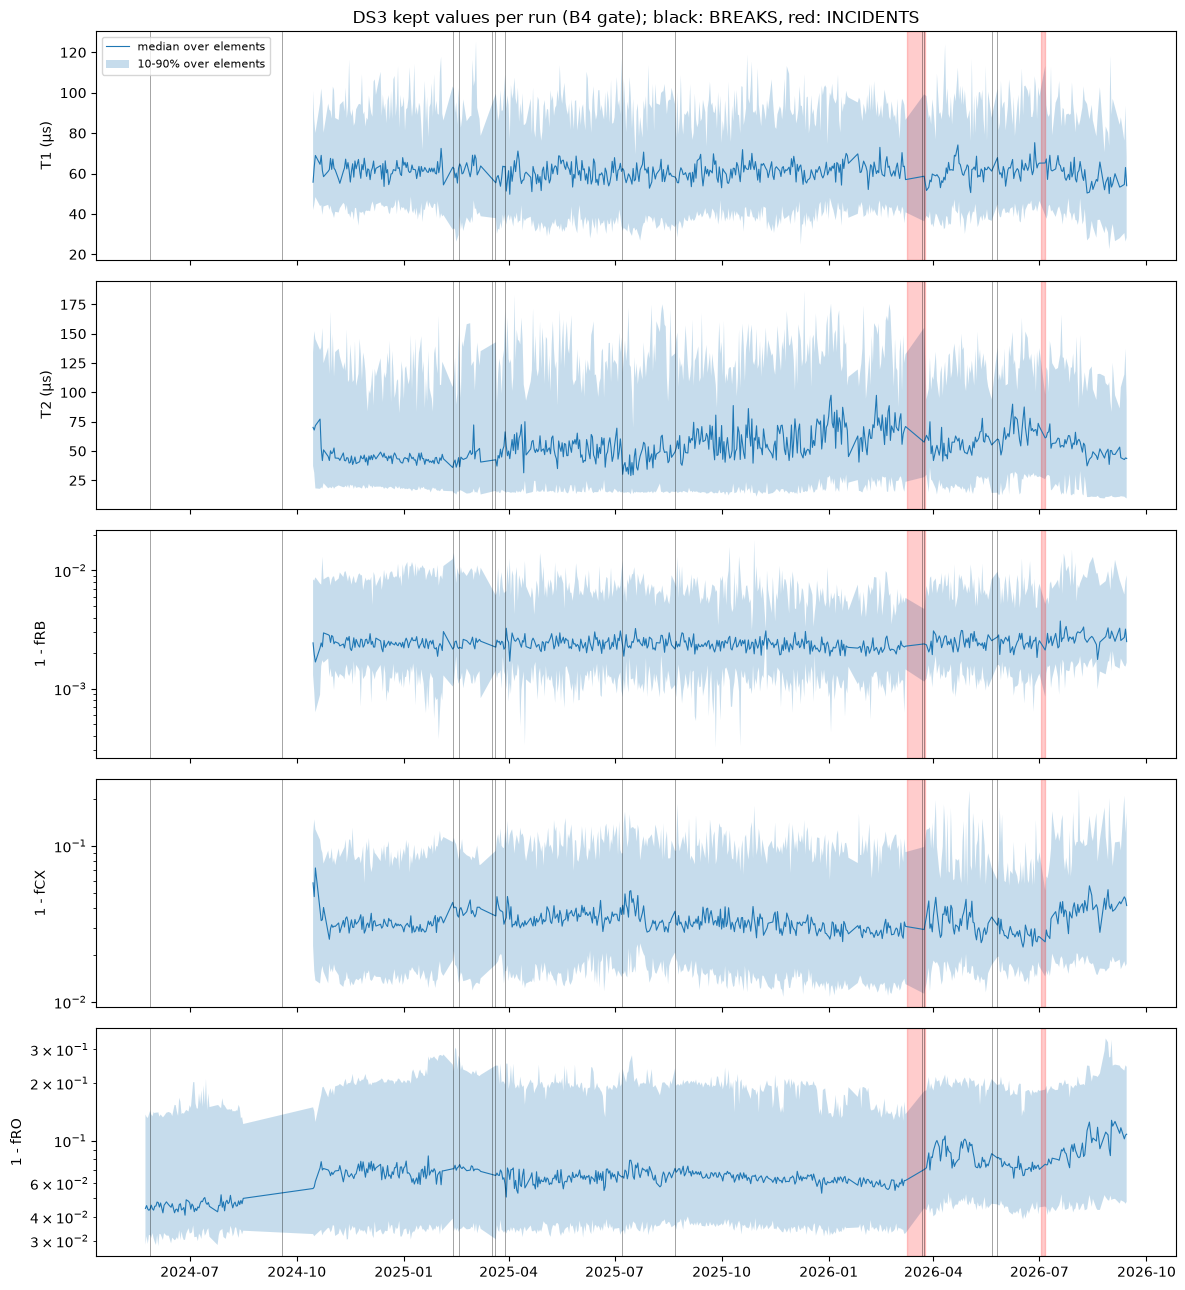

In [5]:
kept = k[k["use"]].copy()
kept["x"] = np.where(kept["metric"].isin(["T1", "T2"]), kept["value_u"] * 1e6, 1 - kept["value_u"])  # µs, or infidelity

# T1 / T2 sweep: config width and pts for the benchmarking payloads, and the x range of one stored fit of each
sw = cfg[(cfg["routine"] == "benchmarking") & cfg["measurement_type"].isin(["T1", "T2echo", "ZMap"])
         & cfg["field"].isin(["width", "pts", "shots"])]
print("benchmarking config settings (payloads per value):")
display(sw.groupby(["measurement_type", "field"])["value"].agg(lambda s: s.value_counts().to_dict()))
for mt in ["T1", "T2"]:
    p = links.loc[(links["metric"] == mt) & links["path"].notna(), "path"].iloc[-1]
    obj = decode.payload(p)
    tgt, node = next(decode.iter_targets(obj))
    x = read_fit(node.get("fit"))["x"]
    print(f"{mt} payload {p.split('/')[-1]} target {tgt}: {len(x)} delays, {x.min():.3g} to {x.max():.3g} s")
# one sweep width for every T1 and T2echo payload (.item() fails if there were more)
SWEEP = sw.loc[sw["measurement_type"].isin(["T1", "T2echo"]) & (sw["field"] == "width"), "value"].astype(float).unique().item()
print(f"delay sweep width: {SWEEP:g} s")
print("kept values per metric: quantiles (T1, T2 in µs; fidelities as 1 - F)")
display(kept.groupby("metric")["x"].quantile([0.01, 0.1, 0.5, 0.9, 0.99]).unstack().round(5)
        .assign(n=kept.groupby("metric").size(), share_T_over_sweep=kept[kept["metric"].isin(["T1", "T2"])]
                .groupby("metric")["value_u"].agg(lambda s: (s > SWEEP).mean()).round(4)))
t12 = kept[kept["metric"].isin(["T1", "T2"])].pivot_table(index=["run", "element"], columns="metric", values="value_u")
t12 = t12.dropna()
print(f"qubit-runs with kept T1 and T2: {len(t12)}; T2 > 2 T1 in {(t12['T2'] > 2 * t12['T1']).mean():.4f},",
      f"T2 > T1 in {(t12['T2'] > t12['T1']).mean():.4f}; median T2 / T1 {(t12['T2'] / t12['T1']).median():.3f}")
print("share of censored values with a value that are above the PHYS_RANGE upper bound (T1, T2) or at or below 0:")
cen = k[(k["cls"] == "censored") & k["value_u"].notna() & k["metric"].isin(["T1", "T2"])]
cen = cen.assign(above_upper=cen["value_u"] > cen["metric"].map(lambda m: PHYS_RANGE[m][1]),
                 at_or_below_0=cen["value_u"] <= 0, above_sweep=cen["value_u"] > SWEEP)
display(cen.groupby(["metric", "status_u"])[["above_upper", "at_or_below_0", "above_sweep"]].mean().round(4)
        .assign(n=cen.groupby(["metric", "status_u"]).size()))

# is r2 a quality check? Rank correlation of r2 with the relative fit error (error / T, or error / (1 - F) for the
# fidelities) on every fit with r2 > 0 and an error, outside INCIDENTS; then the median relative error per r2 band
fq = k[~k["incident"] & (k["r2_u"] > 0) & k["error_u"].notna() & k["metric"].isin(["T1", "T2", "fRB", "fCX"])]
fq = fq.assign(rel_err=fq["error_u"] / np.where(fq["metric"].isin(["T1", "T2"]), fq["value_u"], 1 - fq["value_u"]))
fq = fq[np.isfinite(fq["rel_err"]) & (fq["rel_err"] > 0)]
fq["r2_band"] = pd.cut(fq["r2_u"], [0, 0.5, R2_GATE, 0.95, 0.99, 1])


def rank_corr(d: pd.DataFrame) -> float:
    """Pearson correlation of the ranks of r2 and the relative fit error."""
    return d["r2_u"].rank().corr(d["rel_err"].rank())


cols = ["r2_u", "rel_err"]
print("rank correlation (Pearson on ranks) of r2 with the relative fit error, outside INCIDENTS: all fits and kept rows")
display(pd.DataFrame({"all_fits": fq.groupby("metric")[cols].apply(rank_corr), "n": fq.groupby("metric").size(),
                      "kept": fq[fq["use"]].groupby("metric")[cols].apply(rank_corr),
                      "n_kept": fq[fq["use"]].groupby("metric").size()}).round(3))
print("median relative fit error (rows) per r2 band:")
display(fq.pivot_table(index="metric", columns="r2_band", values="rel_err", aggfunc="median", observed=True).round(3)
        .astype(str) + " (" + fq.pivot_table(index="metric", columns="r2_band", values="rel_err", aggfunc="size",
                                             observed=True).astype(str) + ")")

# fRO: grid of values (DS3 serves fRO rounded to 4 dp, datasheet 3, so the 1/10000 grid says nothing about shots)
ro = k.loc[(k["metric"] == "fRO") & k["value_u"].notna(), "value_u"]
u = np.unique(np.round(ro.to_numpy() * 1e6))
print(f"fRO: {len(ro)} values, {len(u)} distinct at 1e-6; smallest gap between distinct values {np.diff(u).min() / 1e6:.3g};",
      "share on the 1/N grid:", {n: round(float(np.isclose(ro * n, np.round(ro * n), atol=1e-6).mean()), 4) for n in (1000, 2000, 5000, 10000)})

# depolarising floors: 1q RB 1/2, 2q RB 1/4, fRO 1/2
FLOOR = {"fRB": 0.5, "fCX": 0.25, "fRO": 0.5}
fl = k[k["metric"].isin(FLOOR) & k["value_u"].notna()]
fl = fl.assign(floor=fl["metric"].map(FLOOR))
print("values at or below the depolarising floor (+0.02), by B4 status:")
display(pd.crosstab(fl["metric"], [fl["value_u"] <= fl["floor"] + 0.02, fl["status_u"]]))

# spread across elements
em = kept[~kept["settling"]].groupby(["metric", "element"])["x"].median()
print("per-element median of kept values outside SETTLING: spread across elements")
display(em.groupby("metric").describe()[["count", "min", "25%", "50%", "75%", "max"]].round(5))

fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)
day = kept.assign(day=kept["t"].dt.normalize())
for ax, mt in zip(axes, METRICS):
    d = day[day["metric"] == mt].groupby("day")["x"]
    ax.plot(d.median(), lw=0.8, label="median over elements")
    ax.fill_between(d.median().index, d.quantile(0.1), d.quantile(0.9), alpha=0.25, label="10-90% over elements")
    ax.set_ylabel(f"{mt} (µs)" if mt in ("T1", "T2") else f"1 - {mt}")
    if mt not in ("T1", "T2"):
        ax.set_yscale("log")
    for b in periods.BREAKS:
        ax.axvline(b.at, color="k", lw=0.5, alpha=0.5)
    for i in periods.INCIDENTS:
        ax.axvspan(*i.period, color="r", alpha=0.2)
axes[0].legend(loc="upper left", fontsize=8)
axes[0].set_title("DS3 kept values per run (B4 gate); black: BREAKS, red: INCIDENTS")
fig.tight_layout()
fig.savefig(FIG / "b4_kpi_series.png", dpi=120)
plt.show()


**Results.**

- T1 and T2echo sweep 81 delays up to 80 µs, and 0.217 of kept T1 and 0.323 of kept T2 values lie above that. T1's median is 61.1 µs and T2's 53.2 µs.
- T2 > 2 T1 in 0.0989 of 13,059 qubit-runs, and the median T2 / T1 is 0.968.
- r2 ranks the relative fit error on kept T1, fCX and fRB rows (rank correlation −0.587, −0.889, −0.601), but not on T2 (0.079). T2's median relative error is lowest at r2 0.9 to 0.95 (0.086) and rises to 0.129 at 0.95 to 0.99, where most rows are (11,678).
- Median infidelity is fCX 0.0328, fRB 0.00241 and fRO 0.0657.
- Every fRO value is on the 1/10000 grid (20,783 values, 2,978 distinct), and 0.504 are on the 1/5000 grid.
- Within 0.02 of the floor are 95 `ok` fRO values. fCX has 10 `low_r2`, 2 `no_fit` and 2 `no_r2` there, plus 19 `no_result` (the era-0 zeros for couplings that were never measured, DS3 section 6), and no `ok`.
- Per-element medians span T1 32.5 to 91.3 µs, T2 10.4 to 132.5 µs, fCX 0.0102 to 0.189, fRB 0.00086 to 0.0209 and fRO 0.0343 to 0.282. The daily series is in `docs/figures/eda/b4_kpi_series.png`.


## 4. Noise floor

This is the core of B4: does each metric move from run to run by more than its own measurement noise? We group kept values by (metric, element, stratum, fCX list), and take the lag-$L$ sigma as the robust sd of differences between values $L$ DS3 runs apart,

$$\sigma_L = \frac{1.4826\,\operatorname{MAD}(y_{r+L} - y_r)}{\sqrt 2}$$

using pairs in the same group, at most $36L$ h apart and not spanning an `INCIDENTS` start. Against a noise sigma $\sigma_n$ the signal ratio is

$$S_L = \left(\frac{\sigma_L}{\sigma_n}\right)^2$$

A ratio below 1 is undetermined rather than null - noise alone can't give it, so the noise estimate must be too big. Groups need 20+ lag-1 pairs, and a noise estimate 20+ rows.

The main noise estimate differs by metric. T1 and T2 use the fit error (`error`, else `payload_error`). fRB and fCX use `seed_error`, since the RB seeds change every run (3b section 1) so sequence sampling is part of each run's noise. Where it's missing we scale the fit error by the era's median seed / fit ratio on `ok` rows (the ratio depends on fit status, 3d section 4) - fCX takes it from the weekly sample, and we check that out of sample by taking it from the other couplings instead. fRO uses a binomial bound. maac's ZMap prepares $|0\rangle$ and $|1\rangle$ with `shots` each and averages the two fidelities (`maac/measurement/readout/zmaps.py`, `maac/analysis/readout_fitting.py`), and `benchmarking.py` line 231 sets `shots=5000`, so

$$\sigma_\text{RO} \le \sqrt{\frac{F(1-F)}{2 \times 5000}}$$

We also show the signal fraction $1 - (\sigma_n / s)^2$, with $s$ the level's robust sd.


In [6]:
# fRO: maac ZMap (maac/measurement/readout/zmaps.py) prepares |0> and |1>, each with averages x shots single shots, and
# fidelity = 0.5 (g_fidelity + e_fidelity) (docstring; maac/analysis/readout_fitting.py); benchmarking.py 231 calls it with shots=5000
zm = cfg[(cfg["routine"] == "benchmarking") & (cfg["measurement_type"] == "ZMap") & cfg["field"].isin(["shots", "averages"])]
print("benchmarking ZMap shots and averages (payloads per value):", zm.groupby("field")["value"].agg(lambda s: s.value_counts().to_dict()).to_dict())
N_RO = int(sw.loc[(sw["measurement_type"] == "ZMap") & (sw["field"] == "shots"), "value"].astype(int).unique().item())
print(f"fRO is the mean of two binomial fidelities of {N_RO} shots each (times averages, if above 1);",
      f"its sd is at most sqrt(F (1 - F) / (2 x {N_RO})).")
kept["sigma_ro"] = np.where(kept["metric"] == "fRO", np.sqrt(kept["value_u"] * (1 - kept["value_u"]) / (2 * N_RO)), np.nan)
kept["lst"] = kept["list_b4"].fillna("-")
KEY = ["metric", "element", "stratum", "lst"]


def lag_pairs(L: int) -> pd.DataFrame:
    """Kept values L DS3 runs apart, same element, stratum and fCX list, at most L x 36 h apart, not spanning an incident start."""
    a = kept[KEY + ["run", "t", "value_u"]]
    m = a.merge(a.assign(run=a["run"] - L), on=KEY + ["run"], suffixes=("_0", "_1"))
    keep = (m["t_1"] - m["t_0"] <= pd.Timedelta(hours=36 * L)) & ~periods.spans(m["t_0"], m["t_1"], INCIDENT_STARTS)
    return m[keep].assign(d=m["value_u_1"] - m["value_u_0"])


gs = kept.groupby(KEY).agg(n=("value_u", "size"), start=("t", "min"), end=("t", "max"), era=("gating_regime", lambda s: s.mode().iloc[0]),
                           level_rsd=("value_u", rsd), sigma_fit=("error_u", "median"), n_fit=("error_u", "count"),
                           sigma_seed=("seed_error", "median"), n_seed=("seed_error", "count"),
                           sigma_ro=("sigma_ro", "median"), n_ro=("sigma_ro", "count"))
p1 = lag_pairs(1)
gs = gs.join(p1.groupby(KEY)["d"].agg(n_pairs="size", sigma_lag1=lambda d: rsd(d) / np.sqrt(2)))
for e in ["fit", "seed", "ro"]:
    gs.loc[gs[f"n_{e}"] < MIN_N, f"sigma_{e}"] = np.nan
ns = gs[gs["n_pairs"] >= MIN_N].copy()
print(f"element-strata with at least {MIN_N} lag-1 pairs, of all element-strata:",
      ns.groupby(level="metric").size().to_dict(), "of", gs.groupby(level="metric").size().to_dict())
print("lag-1 pairs per metric (after the stratum, list, 36 h and incident-start rules):", p1.groupby("metric").size().to_dict())

# RB seed / fit error ratio per era, on ok rows only: the ratio depends on the fit status (3d section 4), and it scales
# the fit error of kept (ok) rows. fCX on the weekly sample (value_source ds1 left out), fRB on all its payload rows
has_both = (k["cls"] == "ok") & k["seed_error"].notna() & k["error_u"].notna()
smp = k[has_both & (k["metric"] == "fCX") & (k["value_source"] != "ds1")]
rb_ratio = k[has_both & (k["metric"] == "fRB")]
RATIO = {"fCX": (smp["seed_error"] / smp["error_u"]).groupby(smp["gating_regime"]).median(),
         "fRB": (rb_ratio["seed_error"] / rb_ratio["error_u"]).groupby(rb_ratio["gating_regime"]).median()}
print("seed_error / fit error per era, ok rows: median", {mt: r.round(3).to_dict() for mt, r in RATIO.items()},
      "; rows", {"fCX (weekly sample)": smp.groupby("gating_regime").size().to_dict(), "fRB": rb_ratio.groupby("gating_regime").size().to_dict()})
for mt, r in RATIO.items():
    im = ns.index.get_level_values("metric") == mt
    ns.loc[im, "sigma_fitxratio"] = ns.loc[im, "sigma_fit"] * ns.loc[im, "era"].map(r)

# main noise estimate: fit error (T1, T2); RB seeds change every run (3b section 1), so seed_error, else fit error x era
# ratio; binomial (fRO)
is_rb = ns.index.get_level_values("metric").isin(["fRB", "fCX"])
ns["sigma_main"] = np.where(is_rb, ns["sigma_seed"].fillna(ns["sigma_fitxratio"]), ns["sigma_fit"].fillna(ns["sigma_ro"]))
EST = {"main": "sigma_main", "fit": "sigma_fit", "seed": "sigma_seed", "fit x seed ratio": "sigma_fitxratio", "binomial": "sigma_ro"}
for e, c in EST.items():
    ns[f"sr {e}"] = (ns["sigma_lag1"] / ns[c]) ** 2


def sr_summary(d: pd.DataFrame) -> pd.DataFrame:
    """Per noise estimate: element-strata with it, median signal ratio, share reaching 2 and share undetermined (< 1)."""
    out = {}
    for e in EST:
        r = d[f"sr {e}"].dropna()
        if len(r):
            out[e] = {"groups": len(r), "median": r.median(), "share_ge_2": (r >= 2).mean(), "share_lt_1": (r < 1).mean()}
    return pd.DataFrame(out).T


print("signal ratio at lag 1 (one DS3 run), (lag-1 sigma / noise sigma)^2, per metric; main = fit (T1, T2),",
      "seed_error else fit x era seed ratio (fRB, fCX), binomial (fRO):")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(ns.groupby(level="metric").apply(sr_summary))
print("fCX element-strata with 20+ lag-1 pairs per era, by whether they have a main noise estimate:")
fcx_ns = ns.xs("fCX", level="metric")
display(pd.crosstab(fcx_ns["era"], fcx_ns["sigma_main"].notna().map({True: "has estimate", False: "none"})))
print("signal ratio at lag 1 against the main noise estimate, per metric and stratum:")
ns["signal_fraction"] = 1 - (ns["sigma_main"] / ns["level_rsd"]) ** 2
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ns.groupby(level=["metric", "stratum"]).agg(
        groups=("sr main", "count"), sr_median=("sr main", "median"), share_ge_2=("sr main", lambda s: (s.dropna() >= 2).mean()),
        share_lt_1=("sr main", lambda s: (s.dropna() < 1).mean()), signal_fraction_median=("signal_fraction", "median")).dropna(subset=["sr_median"]))
# elements whose main signal ratio is >= 2 in every stratum where it has one
every = ns.dropna(subset=["sr main"]).groupby(level=["metric", "element"])["sr main"].agg(all_ge_2=lambda s: (s >= 2).all(), strata="size")
print("elements with a main signal ratio >= 2 in every stratum they have (of elements with any):")
for mt, g in every.groupby(level="metric"):
    print(f"  {mt}: {int(g['all_ge_2'].sum())} of {len(g)}:", sorted(g[g["all_ge_2"]].index.get_level_values("element")))

# fCX: does the era ratio reproduce seed_error? Out of sample: the ratio from the sample rows of other couplings, same era
both = ns[ns.index.get_level_values("metric") == "fCX"].dropna(subset=["sigma_seed", "sigma_fit"]).copy()
smp_r = smp.assign(r=smp["seed_error"] / smp["error_u"])
both["ratio_loo"] = [smp_r.loc[(smp_r["gating_regime"] == r["era"]) & (smp_r["element"] != idx[1]), "r"].median() for idx, r in both.iterrows()]
q_in = both["sigma_seed"] / both["sigma_fitxratio"]
q_out = both["sigma_seed"] / (both["sigma_fit"] * both["ratio_loo"])
print(f"fCX element-strata with 20+ seed_error rows: {len(both)}; seed_error median over fit error x era ratio:",
      f"in sample median {q_in.median():.3f} ({q_in.quantile(0.1):.3f} to {q_in.quantile(0.9):.3f});",
      f"ratio from other couplings median {q_out.median():.3f} ({q_out.quantile(0.1):.3f} to {q_out.quantile(0.9):.3f})")
print("median sigma per metric over element-strata (T1, T2 in µs):")
sc = ns[["sigma_lag1", "sigma_main", "sigma_fit", "sigma_seed", "sigma_fitxratio", "sigma_ro", "level_rsd"]].copy()
sc[sc.index.get_level_values("metric").isin(["T1", "T2"])] *= 1e6
with pd.option_context("display.float_format", "{:.4g}".format):
    display(sc.groupby(level="metric").median())


benchmarking ZMap shots and averages (payloads per value): {'averages': {'1': 6}, 'shots': {'5000': 6}}
fRO is the mean of two binomial fidelities of 5000 shots each (times averages, if above 1); its sd is at most sqrt(F (1 - F) / (2 x 5000)).


element-strata with at least 20 lag-1 pairs, of all element-strata: {'T1': 183, 'T2': 150, 'fCX': 164, 'fRB': 172, 'fRO': 224} of {'T1': 341, 'T2': 312, 'fCX': 487, 'fRB': 366, 'fRO': 416}
lag-1 pairs per metric (after the stratum, list, 36 h and incident-start rules): {'T1': 14407, 'T2': 11063, 'fCX': 13059, 'fRB': 12638, 'fRO': 18343}
seed_error / fit error per era, ok rows: median {'fCX': {'era1_filter': 1.923, 'era2_ungated': 1.877, 'era3_postproc': 1.881}, 'fRB': {'era1_filter': 1.637, 'era2_ungated': 1.6, 'era3_postproc': 1.634}} ; rows {'fCX (weekly sample)': {'era1_filter': 1053, 'era2_ungated': 174, 'era3_postproc': 1247}, 'fRB': {'era1_filter': 6200, 'era2_ungated': 991, 'era3_postproc': 7907}}
signal ratio at lag 1 (one DS3 run), (lag-1 sigma / noise sigma)^2, per metric; main = fit (T1, T2), seed_error else fit x era seed ratio (fRB, fCX), binomial (fRO):


groups  median  share_ge_2  share_lt_1
metric                                                         
T1     main                 183   3.394      0.8743    0.005464
       fit                  183   3.394      0.8743    0.005464
T2     main                 150   1.467      0.3267      0.3067
       fit                  150   1.467      0.3267      0.3067
fCX    main                 102   1.919      0.4804      0.1471
       fit                  102   7.299       0.951     0.02941
       seed                  28   1.774      0.3929     0.03571
       fit x seed ratio     102   2.062      0.5098      0.1667
fRB    main                 172     1.6      0.3488      0.1163
       fit                  172   4.591      0.9593    0.005814
       seed                 172     1.6      0.3488      0.1163
       fit x seed ratio     172   1.749      0.4186     0.09884
fRO    main                 224   2.953       0.692     0.01786
       binomial             224   2.953       0.692     0.01786

fCX element-strata with 20+ lag-1 pairs per era, by whether they have a main noise estimate:


sigma_main,has estimate,none
era,,
era1_filter,0,62
era2_ungated,26,0
era3_postproc,76,0


signal ratio at lag 1 against the main noise estimate, per metric and stratum:


groups  sr_median  share_ge_2  share_lt_1  signal_fraction_median
metric stratum                                                                                           
T1     11 (2026-03-24)                      29       3.68       0.897           0                   0.789
       13 (2026-05-25)                      29       3.59       0.793      0.0345                   0.806
       2 (2024-09-18)                       32       3.08       0.906           0                   0.756
       7 (2025-03-28)                       31       3.47       0.839           0                   0.762
       8 (2025-07-07)                       31       2.86       0.839           0                   0.739
       9 (2025-08-22)                       31       3.51       0.968           0                   0.797
T2     11 (2026-03-24)                      25       2.06        0.56        0.08                   0.669
       13 (2026-05-25)                      26       1.39       0.231       0.231                   0.628
       2 (2024-09-18)                       29       1.22       0.172       0.414                   0.352
       7 (2025-03-28)                       24       1.57       0.375       0.375                   0.489
       8 (2025-07-07)                       19      0.866       0.158       0.526                   0.208
       9 (2025-08-22)                       27       1.71       0.444       0.259                   0.564
fCX    11 (2026-03-24)                      21       2.11       0.524       0.143                   0.706
       13 (2026-05-25) RB from 2026-06      24       2.34       0.583       0.125                   0.692
       8 (2025-07-07)                       26       2.02         0.5       0.231                   0.556
       9 (2025-08-22)                       31       1.72       0.355      0.0968                   0.516
fRB    11 (2026-03-24)                      27       1.63       0.333       0.185                   0.432
       13 (2026-05-25) RB from 2026-06      29       1.64       0.379       0.138                   0.411
       2 (2024-09-18)                       31       1.39       0.258       0.129                   0.372
       7 (2025-03-28)                       29       1.91       0.448       0.069                   0.464
       8 (2025-07-07)                       26        1.4       0.308       0.192                   0.427
       9 (2025-08-22)                       30       1.58       0.367           0                   0.516
fRO    1 (2024-05-28)                       32       2.41       0.562      0.0312                   0.726
       11 (2026-03-24)                      32       4.86       0.844           0                   0.911
       13 (2026-05-25)                      32       3.15       0.688           0                   0.912
       2 (2024-09-18)                       32          2         0.5      0.0312                   0.763
       7 (2025-03-28)                       32       3.36       0.844           0                   0.853
       8 (2025-07-07)                       32       2.75       0.688      0.0625                   0.772
       9 (2025-08-22)                       32       2.84       0.719           0                   0.865

elements with a main signal ratio >= 2 in every stratum they have (of elements with any):
  T1: 15 of 32: ['1', '10', '11', '13', '15', '17', '19', '20', '22', '24', '25', '28', '4', '5', '7']
  T2: 3 of 32: ['16', '31', '33']
  fCX: 5 of 33: ['10-11', '17-16', '17-25', '19-11', '28-31']
  fRB: 4 of 32: ['20', '25', '33', '34']
  fRO: 6 of 32: ['15', '19', '22', '25', '33', '34']
fCX element-strata with 20+ seed_error rows: 28; seed_error median over fit error x era ratio: in sample median 1.035 (0.693 to 1.259); ratio from other couplings median 1.036 (0.684 to 1.266)
median sigma per metric over element-strata (T1, T2 in µs):


,sigma_lag1,sigma_main,sigma_fit,sigma_seed,sigma_fitxratio,sigma_ro,level_rsd
metric,,,,,,,
T1,10.75,5.887,5.887,NaN,NaN,NaN,12.81
T2,8.683,6.072,6.072,NaN,NaN,NaN,13.25
fCX,0.004835,0.003005,0.001599,0.002997,0.003005,NaN,0.005826
fRB,0.0006839,0.0004897,0.0002973,0.0004897,0.0004813,NaN,0.0006978
fRO,0.004508,0.002458,NaN,NaN,NaN,0.002458,0.006375


**Results.**

- Benchmarking ZMap payloads use 5,000 shots and 1 average, as the binomial bound assumes.
- 183 T1, 150 T2, 164 fCX, 172 fRB and 224 fRO groups have 20+ lag-1 pairs.
- On `ok` rows the seed / fit ratio is 1.877 to 1.923 per era for fCX and 1.600 to 1.637 for fRB.

The lag-1 signal ratio against the main estimate:

| Metric | Main noise | Median | Share ≥ 2 | Share < 1 |
|---|---|---|---|---|
| T1 | fit error | 3.39 | 0.874 | 0.005 |
| T2 | fit error | 1.47 | 0.327 | 0.307 |
| fCX | `seed_error`, else fit × ratio | 1.92 | 0.480 | 0.147 |
| fRB | `seed_error` | 1.60 | 0.349 | 0.116 |
| fRO | binomial | 2.95 | 0.692 | 0.018 |

- Against the fit error alone fCX would be at 7.30 and fRB at 4.59, so the RB fit error on its own would badly overstate the signal.
- Era-1 fCX has no noise estimate: none of its 62 coupling-strata with 20+ pairs has one, while all 26 era-2 and 76 era-3 ones do.
- By stratum the median runs T1 2.86 to 3.68, fRO 2.00 to 4.86, fCX 1.72 to 2.34, fRB 1.39 to 1.91 and T2 0.866 (stratum 8) to 2.06 (stratum 11).
- Reaching 2 in every stratum they have: 15 of 32 T1 qubits, 3 of 32 T2, 5 of 33 fCX couplings, 4 of 32 fRB and 6 of 32 fRO.
- The fCX ratio holds out of sample: `seed_error` over fit × ratio has median 1.036 with the ratio from other couplings, against 1.035 in sample (28 coupling-strata).

Next, a first look at how the spread grows with lag (the structure function, up to 28 runs). If the series were AR(1), with lag-1 correlation $\rho_1 = 1 - (\sigma_1/s)^2$, the variance ratio would follow

$$\frac{\sigma_L^2}{\sigma_1^2} = \frac{1 - \rho_1^L}{1 - \rho_1}$$

and $n\,(1 - \rho_1)/(1 + \rho_1)$ would be its effective sample size. We check that at lag 2. The medians are over whatever groups have 20+ pairs at each lag, so short groups drop out as the lag grows - fine for a profile, but timescales and block lengths need the same series at every lag, which is stage C's job. The cell then writes the DS3 rows to `noise_floor.parquet`, one per method.

In [7]:
# structure function: lag-L spread per element-stratum against its lag-1 spread and main noise sigma; AR(1) from the level spread
LAGS = [1, 2, 3, 4, 7, 14, 28]
ns["rho1"] = 1 - ns["sigma_lag1"] ** 2 / ns["level_rsd"] ** 2  # lag-1 correlation implied by an AR(1)
rows = []
for L in LAGS:
    s = lag_pairs(L).groupby(KEY)["d"].agg(n="size", sL=lambda d: rsd(d) / np.sqrt(2))
    s = s[s["n"] >= MIN_N].join(ns[["sigma_lag1", "sigma_main", "rho1"]], how="inner")
    s["var_ratio"] = (s["sL"] / s["sigma_lag1"]) ** 2
    s["ar1_var_ratio"] = (1 - s["rho1"].clip(-0.99, 0.99) ** L) / (1 - s["rho1"].clip(-0.99, 0.99))
    s["sr"] = (s["sL"] / s["sigma_main"]) ** 2
    for mt, g in s.groupby(level="metric"):
        rows.append({"metric": mt, "lag_runs": L, "groups": len(g), "pairs": int(g["n"].sum()),
                     "var_ratio_to_lag1": g["var_ratio"].median(), "ar1_var_ratio": g["ar1_var_ratio"].median(),
                     "sr_median": g["sr"].median(), "sr_share_ge_2": (g["sr"].dropna() >= 2).mean(),
                     "level_var_over_lag1": ((ns.loc[g.index, "level_rsd"] / g["sigma_lag1"]) ** 2).median()})
sf = pd.DataFrame(rows).set_index(["metric", "lag_runs"])
print("structure function per metric (medians over element-strata with 20+ pairs at that lag); sr is the signal ratio against",
      "the main noise estimate; level_var_over_lag1 is the plateau an AR(1) approaches:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(sf)
lag2 = sf.xs(2, level="lag_runs")
print("lag-2 variance ratio within 10% of AR(1):", ((lag2["var_ratio_to_lag1"] / lag2["ar1_var_ratio"] - 1).abs() <= 0.1).to_dict(),
      "; median lag-1 correlation implied by AR(1):", ns.groupby(level="metric")["rho1"].median().round(3).to_dict())

# noise rows
METHOD = {"sigma_fit": "fit_error_median", "sigma_seed": "seed_error_median", "sigma_fitxratio": "fit_error_median_x_sample_seed_ratio",
          "sigma_lag1": "run_step_robust_sd_over_sqrt2", "sigma_ro": "binomial_upper_median"}
N_COL = {"sigma_fit": "n_fit", "sigma_seed": "n_seed", "sigma_fitxratio": "n_fit", "sigma_lag1": "n_pairs", "sigma_ro": "n_ro"}
nf = pd.DataFrame([{"source": "ds3", "param": mt, "entity": el, "regime": st if lst == "-" else f"{st}, {lst} list",
                    "start": r["start"], "end": r["end"], "method": method, "sigma": r[col], "unit": UNIT[mt], "n": int(r[N_COL[col]])}
                   for (mt, el, st, lst), r in ns.iterrows() for col, method in METHOD.items() if pd.notna(r[col])])
table = write_noise_rows(nf, "ds3")
print(f"{len(nf)} DS3 rows written, per method:", nf.groupby("method").size().to_dict(),
      "; noise_floor.parquet now holds:", table.groupby("source").size().to_dict())

structure function per metric (medians over element-strata with 20+ pairs at that lag); sr is the signal ratio against the main noise estimate; level_var_over_lag1 is the plateau an AR(1) approaches:


,,groups,pairs,var_ratio_to_lag1,ar1_var_ratio,sr_median,sr_share_ge_2,level_var_over_lag1
metric,lag_runs,,,,,,,
T1,1,183,13658,1,1,3.39,0.874,1.37
T2,1,150,10326,1,1,1.47,0.327,1.38
fCX,1,164,12045,1,1,1.92,0.48,1.27
fRB,1,172,11737,1,1,1.6,0.349,1.1
fRO,1,224,17451,1,1,2.95,0.692,1.87
T1,2,181,13244,1.09,1.28,3.81,0.89,1.38
T2,2,148,10002,1.08,1.27,1.65,0.324,1.38
fCX,2,160,11602,1.08,1.21,2.2,0.53,1.27
fRB,2,172,11385,1.05,1.09,1.6,0.337,1.1


lag-2 variance ratio within 10% of AR(1): {'T1': False, 'T2': False, 'fCX': False, 'fRB': True, 'fRO': False} ; median lag-1 correlation implied by AR(1): {'T1': 0.272, 'T2': 0.273, 'fCX': 0.211, 'fRB': 0.093, 'fRO': 0.465}
2198 DS3 rows written, per method: {'binomial_upper_median': 224, 'fit_error_median': 607, 'fit_error_median_x_sample_seed_ratio': 274, 'run_step_robust_sd_over_sqrt2': 893, 'seed_error_median': 200} ; noise_floor.parquet now holds: {'ds1_1q': 1674, 'ds2': 1679, 'ds3': 2198, 'ds4': 120}


**Results.**

- The spread keeps growing with lag: at 28 runs the variance ratio to lag 1 is 1.44 (T1), 1.52 (T2), 1.34 (fCX), 1.11 (fRB) and 2.03 (fRO).
- It isn't AR(1). At lag 2 every metric sits below the AR(1) value (1.05 to 1.20 against 1.09 to 1.47), and only fRB is within 10% of it, so AR(1) effective sample sizes are out.
- T2's median signal ratio climbs from 1.47 at lag 1 to 2.07 at lag 28.
- Only 0.52 (fRB) to 0.71 (fRO) of the groups reach lag 28, so the long-lag medians lean on the longer series.
- We write 2,198 DS3 rows to `noise_floor.parquet`, which now holds ds1_1q 1,674, ds2 1,679, ds3 2,198 and ds4 120.

## 5. Stationarity screen

Do levels shift, and if so, when? We work on each kept series on the log scale ($\log_{10}$ of T1 and T2, or of the infidelity), centred per element, and start with monthly medians. Then a simple change-point screen per element-stratum, with windows that never cross a stratum boundary:

$$z_r = \frac{\operatorname{med}(y_{r+1}, \dots, y_{r+7}) - \operatorname{med}(y_{r-6}, \dots, y_r)}{s}$$

with $s$ the element-stratum robust sd. Candidates have $|z| > 2$ and sit at least 7 runs apart. A candidate matches when a register event (`periods.py` and the B1 thermal cycles) lies within 2 days, and chance is the share of eligible times within 2 days of any event. It's shared when candidates within 2 days of each other cover at least a quarter of the metric's elements. For fCX we also check change points against the coupling's own list switches, and look at the level around 2024-10 directly - from the first kept run (2024-10-15), since era 0 has none.


In [8]:
kept["lx"] = np.log10(kept["x"].where(kept["x"] > 0))
kept["lx_c"] = kept["lx"] - kept.groupby(["metric", "element"])["lx"].transform("median")
print("monthly median over kept rows of log10 value (T1, T2) or log10 infidelity, centred per element; SETTLING rows left out:")
mon = kept[~kept["settling"]].pivot_table(index=kept["t"].dt.to_period("M"), columns="metric", values="lx_c", aggfunc="median")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(mon.join(kept.groupby(kept["t"].dt.to_period("M"))["run"].nunique().rename("runs")))

# change points per element and stratum on the log series (windows never cross a stratum boundary):
# median of the next 7 kept runs minus the previous 7, over the element-stratum robust sd
W, THR, NEAR = 7, 2.0, pd.Timedelta("2D")
EVENTS = ([(b.at, f"BREAK {b.at:%Y-%m-%d} {b.what}") for b in periods.BREAKS]
          + [(a, f"OUTAGE {w}") for a, b in periods.OUTAGES for a, w in ((a, "start"), (b, "end"))]
          + [(a, f"DS4_GAP {w}") for a, b in periods.DS4_GAPS for a, w in ((a, "start"), (b, "end"))]
          + [(u.at, "UNTRACKED_DS2") for u in periods.UNTRACKED_DS2] + [(pd.Timestamp(a), "UNTRACKED_DS2_OTHER") for a in periods.UNTRACKED_DS2_OTHER]
          + [(p, f"F01_FLAG {w}") for f in periods.F01_FLAGS for p, w in zip(f.period, ("start", "end"))]
          + [(p, f"INCIDENT {w}") for i in periods.INCIDENTS for p, w in zip(i.period, ("start", "end"))]
          + [(p, f"THERMAL_CYCLE {w}") for c in periods.THERMAL_CYCLES for p, w in zip(c, ("start", "end"))])
ev_t = pd.Series([pd.Timestamp(a) for a, _ in EVENTS])


def match(t: pd.Timestamp) -> str:
    """Register events within 2 days of t."""
    return "; ".join(sorted({w for a, w in EVENTS if abs(pd.Timestamp(a) - t) <= NEAR}))


cands, elig = [], []
for (mt, el, st), g in kept.dropna(subset=["lx"]).sort_values("run").groupby(["metric", "element", "stratum"]):
    s = g.set_index("run")["lx"]
    before = s.rolling(W, min_periods=5).median()
    after = s[::-1].rolling(W, min_periods=5).median()[::-1].shift(-1)
    z = ((after - before) / rsd(s)).dropna()
    tt = g.set_index("run")["t"].shift(-1)
    elig += [{"metric": mt, "t": x} for x in tt[z.index].dropna()]  # times a candidate could take
    pos = pd.Series(np.arange(len(s)), index=s.index)
    while len(z) and z.abs().max() > THR:
        r = z.abs().idxmax()
        cands.append({"metric": mt, "element": el, "stratum": st, "t": tt[r], "z": z[r]})
        z = z[(pos[z.index] - pos[r]).abs() > W]
cp = pd.DataFrame(cands).dropna(subset=["t"]).sort_values(["metric", "t"])
cp["event"] = cp["t"].map(match)
elig = pd.DataFrame(elig)
elig["near"] = np.abs(elig["t"].to_numpy()[:, None] - ev_t.to_numpy()[None, :]).min(1) <= NEAR
print(f"change points per element-stratum at |z| > {THR} (7-run windows, candidates 7 kept runs apart); share matching a register",
      "event within 2 days, against chance: the share of eligible times (both windows filled) within 2 days of any event:")
display(cp.groupby("metric").agg(candidates=("z", "size"), elements=("element", "nunique"), matched=("event", lambda s: (s != "").mean()))
        .join(elig.groupby("metric")["near"].mean().rename("chance")).round(3))
cp["cluster"] = cp.groupby("metric")["t"].transform(lambda s: (s.diff() > NEAR).cumsum())
cl = cp.groupby(["metric", "cluster"]).agg(first=("t", "min"), last=("t", "max"), elements=("element", "nunique"),
                                           median_z=("z", "median"))
n_el = kept.groupby("metric")["element"].nunique()
cl = cl[cl["elements"] >= 0.25 * n_el.reindex(cl.index.get_level_values("metric")).to_numpy()]
cl["event"] = [match(a + (b - a) / 2) for a, b in zip(cl["first"], cl["last"])]
print("shared change points: candidates within 2 days of each other on at least a quarter of the elements:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cl.reset_index(level="cluster", drop=True))

# fCX level around 2024-10 (no fCX value before 2024-10-15 is kept: era 0 has no R² anywhere): per coupling median
# infidelity in each window, then the median over couplings
FCX_WIN = {"2024-10-15 to 10-17": ("2024-10-15", "2024-10-18"), "2024-10-21 to 10-27": ("2024-10-21", "2024-10-28"),
           "2024-10-28 to 11-30": ("2024-10-28", "2024-12-01")}
fw = kept[kept["metric"] == "fCX"]
fwm = pd.DataFrame({n: fw[(fw["t"] >= a) & (fw["t"] < b)].groupby("element")["x"].median() for n, (a, b) in FCX_WIN.items()})
print("fCX infidelity around 2024-10, median over couplings of per-coupling medians (couplings with all windows), and runs per window:")
display(pd.DataFrame({"median_infidelity": fwm.dropna().median(), "couplings": len(fwm.dropna()),
                      "runs": {n: fw[(fw["t"] >= a) & (fw["t"] < b)]["run"].nunique() for n, (a, b) in FCX_WIN.items()}}).round(4))

# fCX: candidates at a list switch of the same coupling (within 2 days)
fk = kept[kept["metric"] == "fCX"].sort_values(["element", "run"])
sw_runs = fk[fk["list_b4"] != fk.groupby("element")["list_b4"].shift()].groupby("element")["t"].apply(list)
fcp = cp[cp["metric"] == "fCX"].copy()
fcp["at_list_switch"] = [any(abs(t - s) <= NEAR for s in sw_runs.get(e, [])[1:]) for e, t in zip(fcp["element"], fcp["t"])]
fk_sw = [any(abs(t - s) <= NEAR for s in sw_runs.get(e, [])[1:]) for e, t in zip(fk["element"], fk["t"])]
print(f"fCX change points within 2 days of the coupling's own list switch: {fcp['at_list_switch'].mean():.3f} of {len(fcp)};",
      f"kept fCX rows within 2 days of one: {np.mean(fk_sw):.3f}; list switches per coupling: median",
      f"{sw_runs.map(len).sub(1).median():.0f}, max {sw_runs.map(len).sub(1).max()}")


monthly median over kept rows of log10 value (T1, T2) or log10 infidelity, centred per element; SETTLING rows left out:


,T1,T2,fCX,fRB,fRO,runs
t,,,,,,
2024-05,NaN,NaN,NaN,NaN,-0.080,8
2024-06,NaN,NaN,NaN,NaN,-0.082,24
2024-07,NaN,NaN,NaN,NaN,-0.072,25
2024-08,NaN,NaN,NaN,NaN,-0.068,16
2024-10,0.027,0.025,0.000,-0.006,-0.019,11
2024-11,0.005,0.006,-0.041,-0.005,0.002,25
2024-12,0.001,-0.010,-0.031,-0.005,0.006,28
2025-01,0.011,-0.006,-0.024,-0.014,0.006,31
2025-02,-0.007,-0.037,0.002,-0.019,0.039,17


change points per element-stratum at |z| > 2.0 (7-run windows, candidates 7 kept runs apart); share matching a register event within 2 days, against chance: the share of eligible times (both windows filled) within 2 days of any event:


,candidates,elements,matched,chance
metric,,,,
T1,91,28,0.011,0.047
T2,117,27,0.017,0.045
fCX,73,28,0.041,0.048
fRB,64,26,0.000,0.049
fRO,218,31,0.050,0.041


shared change points: candidates within 2 days of each other on at least a quarter of the elements:


,first,last,elements,median_z,event
metric,,,,,
T2,2024-10-23 18:35:24,2024-10-24 18:35:10,11,-5.82,
fRO,2024-10-23 18:35:24,2024-10-24 18:35:10,11,5.32,
fRO,2025-06-14 20:14:21,2025-06-18 20:14:18,9,-6.11,
fRO,2025-06-24 20:14:23,2025-06-27 20:14:21,10,4.14,
fRO,2026-05-04 20:15:22,2026-05-09 20:12:40,8,-2.27,


fCX infidelity around 2024-10, median over couplings of per-coupling medians (couplings with all windows), and runs per window:


,median_infidelity,couplings,runs
2024-10-15 to 10-17,0.0538,30,3
2024-10-21 to 10-27,0.0374,30,4
2024-10-28 to 11-30,0.0315,30,29


fCX change points within 2 days of the coupling's own list switch: 0.301 of 73; kept fCX rows within 2 days of one: 0.139; list switches per coupling: median 18, max 148


**Results.**

- In the centred monthly medians fRO sits at −0.082 to −0.068 in 2024-05 to 08 and 0.024 to 0.128 from 2026-04, and T2 at 0.024 to 0.081 in 2026-01 to 07.
- Change points match a register event no more often than chance: T1 0.011 against 0.047, T2 0.017 against 0.045, fCX 0.041 against 0.048, fRB 0 against 0.049 and fRO 0.050 against 0.041.
- T2 and fRO, each on 11 qubits, share a change point on 2024-10-23/24 that matches no event. fRO also shares three unmatched ones in 2025-06 (twice) and 2026-05. fCX shares none.
- fCX infidelity drops through 2024-10: median 0.0538 on 10-15 to 10-17 (3 runs), 0.0374 on 10-21 to 10-27 and 0.0315 on 10-28 to 11-30.
- 0.301 of the 73 fCX change points fall within 2 days of the coupling's own list switch, against 0.139 of kept fCX rows.

The second cell compares each element before and after the 2026-03 thermal cycle (strata 7 to 9 against 11 to 13, 20+ lag-1 pairs on each side): level, lag-1 sigma and fit error. For fCX we test the change against the DS2 `cr_scale` phase move (B2 section 5) with a rank correlation and 10,000 shuffles. Then RB either side of 2026-06, where the durations step (3a section 3), and last a consistency check - DS3's openpulse drive frames should equal the DS2 drive frequency, which only runs to 2026-08-18 (A3).


In [9]:
# before / after the thermal cycle, per element: strata 7-9 against 11-13 (SETTLING left out)
PRE, POST = {7, 8, 9}, {11, 12, 13}
kept["era_tc"] = np.select([kept["segment"].isin(PRE) & ~kept["settling"], kept["segment"].isin(POST) & ~kept["settling"]], ["pre", "post"], "")
p1e = p1.merge(kept[["metric", "element", "run", "era_tc"]], on=["metric", "element", "run"])
tc = kept[kept["era_tc"] != ""].groupby(["metric", "element", "era_tc"]).agg(n=("x", "size"), level=("x", "median"), fit=("error_u", "median"))
tc = tc.join(p1e[p1e["era_tc"] != ""].groupby(["metric", "element", "era_tc"])["d"].agg(n_pairs="size", lag1=lambda d: rsd(d) / np.sqrt(2)))
tc = tc.unstack("era_tc")
tc = tc[(tc[("n_pairs", "pre")] >= MIN_N) & (tc[("n_pairs", "post")] >= MIN_N)]
rat = pd.DataFrame({c: tc[(c, "post")] / tc[(c, "pre")] for c in ["level", "lag1", "fit"]})
print("per element, post / pre ratio (level: T1, T2 value or infidelity; lag1: lag-1 sigma; fit: median fit error):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(rat.groupby(level="metric").agg(["count", "median", lambda s: (s > 1).mean()])
            .rename(columns={"<lambda_0>": "share_up"}))

# fCX against the cr_scale phase move: DS2 cr_scale in force at each kept fCX run, median arg per coupling pre and post
val = load_values()
cr = val[val["path"].str.contains(r"\.cross_resonance\}\.pulse_channel\.scale", regex=True)].copy()
ct = cr["path"].str.extract(r"Ch\d+\.Q(\d+)\.Q(\d+)\.cross_resonance\}")
cr["element"] = ct[0] + "-" + ct[1]
cr["arg"] = [np.angle(complex(*v)) for v in cr["value_json"].map(json.loads)]
LAST_DS2 = val["valid_from_ts"].max()
fr = kept[(kept["metric"] == "fCX") & (kept["era_tc"] != "") & (kept["created_at"] <= LAST_DS2)][["element", "created_at", "era_tc", "x"]]
fr = pd.merge_asof(fr.sort_values("created_at").astype({"created_at": "datetime64[us]"}),
                   cr[["element", "valid_from_ts", "valid_to_ts", "arg"]].sort_values("valid_from_ts").astype({"valid_from_ts": "datetime64[us]"}),
                   left_on="created_at", right_on="valid_from_ts", by="element", direction="backward")
fr = fr[fr["valid_to_ts"].isna() | (fr["created_at"] < fr["valid_to_ts"])]
ph = fr.groupby(["element", "era_tc"]).agg(arg=("arg", "median"), x=("x", "median"), n=("x", "size")).unstack("era_tc").dropna()
ph = ph[(ph[("n", "pre")] >= MIN_N) & (ph[("n", "post")] >= MIN_N)]
move = pd.Series(np.abs(np.angle(np.exp(1j * (ph[("arg", "post")] - ph[("arg", "pre")])))), index=ph.index)
lr = np.log(ph[("x", "post")] / ph[("x", "pre")])
rc = move.rank().corr(lr.rank())
rng = np.random.default_rng(0)
perm = np.array([np.corrcoef(move.rank(), rng.permutation(lr.rank().to_numpy()))[0, 1] for _ in range(10000)])
print(f"fCX couplings with 20+ kept runs pre and post and a DS2 cr_scale: {len(ph)}; |median arg move| > 0.1 rad on {(move > 0.1).sum()};",
      f"rank correlation (Pearson on ranks) of |move| with log infidelity ratio {rc:.3f}, two-sided permutation p {(np.abs(perm) >= abs(rc)).mean():.3f}",
      f"(10,000 shuffles); median infidelity ratio post / pre {np.exp(lr[move > 0.1].median()):.3f} (move > 0.1) and {np.exp(lr[move <= 0.1].median()):.3f} (<= 0.1)")

# RB either side of 2026-06: SETTLING end to 2026-06-01 against 2026-06-01 on (INCIDENTS already out)
rb = kept[kept["metric"].isin(["fRB", "fCX"]) & (kept["t"] >= periods.SETTLING[0][1])].copy()
rb["side"] = np.where(rb["t"] < RB_JUNE, "before", "from 2026-06")
jj = rb.groupby(["metric", "element", "side"]).agg(n=("x", "size"), infid=("x", "median"), fit=("error_u", "median"),
                                                     seed=("seed_error", "median"), n_seed=("seed_error", "count")).unstack("side")
jj = jj[(jj[("n", "before")] >= 10) & (jj[("n", "from 2026-06")] >= 10)]
jr = pd.DataFrame({c: jj[(c, "from 2026-06")] / jj[(c, "before")] for c in ["infid", "fit", "seed"]})
print(f"RB per element, 2026-06 on / {periods.SETTLING[0][1]:%Y-%m-%d} to 2026-05-31 (10+ kept runs each side); runs per side:",
      rb.groupby("side")["run"].nunique().to_dict())
with pd.option_context("display.float_format", "{:.3g}".format):
    display(jr.groupby(level="metric").agg(["count", "median", lambda s: (s > 1).mean()]).rename(columns={"<lambda_0>": "share_up"}))

# frames: DS3 drive frame frequency against the DS2 drive frequency in force at the run's created_at
RAW_JSON = RAW / "benchmarking" / "benchmarking_json"
fq = []
for t in runs.loc[runs["has_openpulse"], "created_at"]:
    p = RAW_JSON / f"{t:%Y-%m-%dT%H%M%S_%f}.json"
    frames = json.loads(p.read_text())["openpulse_features"]["open_pulse"]["frames"]
    fq += [{"created_at": t, "q": n[1:-6], "frame": f["frequency"]} for n, f in frames.items() if n.endswith("_drive")]
fq = pd.DataFrame(fq)
dv = val[val["path"].str.contains(r"\.drive\}\.pulse_channel\.frequency", regex=True)].copy()
dv["q"] = dv["path"].str.extract(r"\.Q(\d+)\.drive\}")[0]
fq = fq[fq["created_at"] <= LAST_DS2].sort_values("created_at").astype({"created_at": "datetime64[us]"})
fq = pd.merge_asof(fq, dv[["q", "valid_from_ts", "valid_to_ts", "value_float"]].sort_values("valid_from_ts").astype({"valid_from_ts": "datetime64[us]"}),
                   left_on="created_at", right_on="valid_from_ts", by="q", direction="backward")
fq = fq[fq["valid_to_ts"].isna() | (fq["created_at"] < fq["valid_to_ts"])]
fq["diff_hz"] = fq["frame"] - fq["value_float"]
print(f"openpulse runs {runs['has_openpulse'].sum()} ({runs.loc[runs['has_openpulse'], 'created_at'].min():%Y-%m-%d} on); drive frames",
      f"to the last DS2 snapshot {LAST_DS2}: {len(fq)} on {fq['created_at'].nunique()} runs; |frame - DS2| <= 1 Hz in",
      f"{(fq['diff_hz'].abs() <= 1).mean():.4f}; max |diff| {fq['diff_hz'].abs().max():.4g} Hz")
if (fq["diff_hz"].abs() > 1).any():
    display(fq[fq["diff_hz"].abs() > 1].groupby("created_at").agg(qubits=("q", "size"), max_abs_hz=("diff_hz", lambda s: s.abs().max())))

per element, post / pre ratio (level: T1, T2 value or infidelity; lag1: lag-1 sigma; fit: median fit error):


level                  lag1                   fit                
       count median share_up count median share_up count median share_up
metric                                                                  
T1        31   1.04    0.613    31   1.05    0.613    31   1.12    0.677
T2        26   1.13    0.577    26   1.37    0.731    26   1.11    0.577
fCX       22  0.873    0.409    22   1.05    0.545    22   1.01      0.5
fRB       28  0.986    0.464    28  0.895    0.429    28  0.927    0.393
fRO       32   1.19    0.625    32    1.2    0.719     0    NaN        0

fCX couplings with 20+ kept runs pre and post and a DS2 cr_scale: 23; |median arg move| > 0.1 rad on 16; rank correlation (Pearson on ranks) of |move| with log infidelity ratio 0.241, two-sided permutation p 0.269 (10,000 shuffles); median infidelity ratio post / pre 0.942 (move > 0.1) and 0.715 (<= 0.1)
RB per element, 2026-06 on / 2026-04-04 to 2026-05-31 (10+ kept runs each side); runs per side: {'before': 50, 'from 2026-06': 77}


infid                   fit                  seed                
       count median share_up count median share_up count median share_up
metric                                                                  
fCX       25   1.03      0.6    25   0.98      0.4    25   0.93     0.36
fRB       32   1.01    0.531    32   1.01      0.5    32  0.991      0.5

openpulse runs 85 (2026-05-21 on); drive frames to the last DS2 snapshot 2026-08-18 09:13:31: 2208 on 69 runs; |frame - DS2| <= 1 Hz in 1.0000; max |diff| 0 Hz


**Results.**

- After / before the thermal cycle, per element (level; lag-1 sigma): T1 1.04, 1.05; T2 1.13, 1.37 (fit error 1.11); fCX infidelity 0.873, 1.05; fRB 0.986, 0.895; fRO 1.19, 1.2.
- 16 of 23 couplings moved their `cr_scale` phase by more than 0.1 rad, but the move barely tracks the fCX change (rank correlation 0.241, p 0.269).
- RB from 2026-06 against 2026-04-04 to 05-31 (value; fit error; `seed_error`): fCX 1.03, 0.98, 0.93; fRB 1.01, 1.01, 0.991.
- All 2,208 drive frames on 69 runs up to the last DS2 snapshot equal the DS2 drive frequency (max difference 0 Hz). Openpulse runs start on 2026-05-21.


## 6. Checks for Phases C and D

A few things the next phases need before they start. First, coverage: which metric-strata have a main noise estimate (section 4) for their element-strata with 20+ lag-1 pairs - that's where stage C can begin.


In [10]:
# where each metric has a main noise estimate: kept runs per stratum, and element-strata with 20+ lag-1 pairs (section 4)
def by_stratum(i: pd.Index) -> pd.Index:
    """Order strata by their number, settling last."""
    return pd.Index([int(s.split()[0]) if s[0].isdigit() else 99 for s in i])


kr = kept.groupby(["stratum", "metric"])["run"].nunique().unstack("metric").reindex(columns=METRICS)
cvg = ns.assign(has_main=ns["sigma_main"].notna()).groupby(level=["stratum", "metric"])["has_main"].agg(["sum", "size"])
cvg = (cvg["sum"].astype(int).astype(str) + " / " + cvg["size"].astype(str)).unstack("metric").reindex(columns=METRICS)
span = kept.groupby("stratum")["t"].agg(first="min", last="max").apply(lambda s: s.dt.strftime("%Y-%m-%d"))
print("per stratum: kept-row span, kept runs per metric, and element-strata with a main noise estimate / with 20+ lag-1 pairs:")
display(span.join(kr.add_prefix("runs ").astype("Int64").astype(object)).join(cvg.add_prefix("main / groups "))
        .fillna("-").sort_index(key=by_stratum))
print("earliest kept time of an element-stratum with 20+ lag-1 pairs, and of one with a main noise estimate:")
display(pd.DataFrame({"with_20_pairs": ns.groupby(level="metric")["start"].min(),
                      "with_main": ns[ns["sigma_main"].notna()].groupby(level="metric")["start"].min()}).reindex(METRICS))
has = kept.join(ns["sigma_main"].notna().rename("has_main"), on=KEY)["has_main"].eq(True)
print("share of kept rows in an element-stratum with a main noise estimate:", has.groupby(kept["metric"]).mean().round(3).to_dict())


per stratum: kept-row span, kept runs per metric, and element-strata with a main noise estimate / with 20+ lag-1 pairs:


,first,last,runs T1,runs T2,runs fRB,runs fCX,runs fRO,main / groups T1,main / groups T2,main / groups fRB,main / groups fCX,main / groups fRO
stratum,,,,,,,,,,,,
0 (start),2024-05-24,2024-05-27,-,-,-,-,4,-,-,-,-,-
1 (2024-05-28),2024-05-28,2024-08-16,-,-,-,-,69,-,-,-,-,32 / 32
2 (2024-09-18),2024-10-15,2025-02-04,99,99,99,99,99,32 / 32,29 / 29,31 / 31,0 / 31,32 / 32
3 (2025-02-12),2025-02-12,2025-02-16,5,5,5,5,5,-,-,-,-,-
4 (2025-02-17),2025-02-17,2025-03-08,15,15,15,15,15,-,-,-,-,-
6 (2025-03-20),2025-03-21,2025-03-27,7,7,7,7,7,-,-,-,-,-
7 (2025-03-28),2025-03-28,2025-07-06,97,97,97,97,97,31 / 31,24 / 24,29 / 29,0 / 31,32 / 32
8 (2025-07-07),2025-07-07,2025-08-19,40,40,40,40,40,31 / 31,19 / 19,26 / 26,26 / 26,32 / 32
9 (2025-08-22),2025-08-22,2026-03-08,180,180,180,179,180,31 / 31,27 / 27,30 / 30,31 / 31,32 / 32


earliest kept time of an element-stratum with 20+ lag-1 pairs, and of one with a main noise estimate:


,with_20_pairs,with_main
metric,,
T1,2024-10-15 14:46:30.000000,2024-10-15 14:46:30.000000
T2,2024-10-15 14:46:30.000000,2024-10-15 14:46:30.000000
fRB,2024-10-15 14:46:30.000000,2024-10-15 14:46:30.000000
fCX,2024-10-15 14:46:30.000000,2025-07-07 20:13:08.000000
fRO,2024-05-28 20:10:56.372690,2024-05-28 20:10:56.372690


share of kept rows in an element-stratum with a main noise estimate: {'T1': 0.929, 'T2': 0.902, 'fCX': 0.532, 'fRB': 0.905, 'fRO': 0.938}


**Results.**

- Strata 0 and 1 have kept rows only for fRO, and T1, T2, fRB and fCX start in stratum 2. fCX has no main estimate in strata 2 and 7, and from stratum 8 on every element-stratum with 20+ pairs has one.
- Strata 3, 4, 6 and 12 (5, 15, 7 and 1 runs) and `SETTLING` (8 runs) have no element-stratum with 20+ pairs, and strata 5 and 10 have no runs.
- So a main estimate starts on 2024-10-15 for T1, T2 and fRB, 2025-07-07 for fCX and 2024-05-28 for fRO, and covers T1 0.929, T2 0.902, fRB 0.905, fCX 0.532 and fRO 0.938 of kept rows.

Then T2's low signal ratio - is it about the level? We bin T1 and T2 element-strata by median level and recompute the ratio on the log scale too, $\left(\sigma_1(\ln T) \,/\, \operatorname{med}(\sigma/T)\right)^2$.

In [11]:
# T1 and T2: signal ratio against the element-stratum level and the 80 µs sweep, on the raw scale (section 4) and the log scale
tk = kept[kept["metric"].isin(["T1", "T2"])].assign(rel_err=lambda d: d["error_u"] / d["value_u"])
lv = tk.groupby(KEY).agg(median_us=("x", "median"), share_above_sweep=("value_u", lambda s: (s > SWEEP).mean()),
                         rel_fit=("rel_err", "median"), n_rel=("rel_err", "count"))
lv.loc[lv["n_rel"] < MIN_N, "rel_fit"] = np.nan
pl = p1[p1["metric"].isin(["T1", "T2"])]
dl = np.log(pl["value_u_1"]) - np.log(pl["value_u_0"])  # lag-1 step of ln T; its sd / sqrt(2) against error / T
lv = lv.join(dl.groupby([pl[c] for c in KEY]).agg(lambda d: rsd(d) / np.sqrt(2)).rename("sigma_lag1_log"))
tl = ns.join(lv, how="inner")
tl["sr_log"] = (tl["sigma_lag1_log"] / tl["rel_fit"]) ** 2
level_bin = pd.cut(tl["median_us"], [0, 40, 60, 80, 120, np.inf], labels=["< 40 µs", "40-60", "60-80", "80-120", "> 120"]).to_numpy()


def sr_cols(d: pd.DataFrame) -> pd.Series:
    """Groups, median level terms and signal ratio (raw and log) for a set of element-strata."""
    g, gl = d["sr main"].dropna(), d["sr_log"].dropna()
    return pd.Series({"groups": len(d), "share_above_sweep": d["share_above_sweep"].median(),
                      "sigma_lag1_us": d["sigma_lag1"].median() * 1e6, "sigma_fit_us": d["sigma_fit"].median() * 1e6,
                      "rel_fit": d["rel_fit"].median(), "sr_median": g.median(), "sr_share_ge_2": (g >= 2).mean(),
                      "sr_share_lt_1": (g < 1).mean(), "sr_log_median": gl.median(), "sr_log_share_ge_2": (gl >= 2).mean(),
                      "sr_log_share_lt_1": (gl < 1).mean()})


print("T1 and T2 element-strata (20+ lag-1 pairs) by median kept value; medians of the share above the sweep, sigmas and",
      "relative fit error; signal ratio raw = (lag-1 sigma / fit error)^2, log = (lag-1 sigma of ln T / median error / T)^2:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tl.groupby([tl.index.get_level_values("metric").rename("metric"), pd.Index(level_bin, name="median_level")], observed=True)
            .apply(sr_cols))
    print("all element-strata:")
    display(tl.groupby(level="metric").apply(sr_cols))
print("rank correlation over element-strata with the median level (Pearson on ranks):",
      {mt: {c: round(float(g[c].rank().corr(g["median_us"].rank())), 3) for c in ["sr main", "sr_log", "sigma_fit", "rel_fit"]}
       for mt, g in tl.groupby(level="metric")})


T1 and T2 element-strata (20+ lag-1 pairs) by median kept value; medians of the share above the sweep, sigmas and relative fit error; signal ratio raw = (lag-1 sigma / fit error)^2, log = (lag-1 sigma of ln T / median error / T)^2:


groups  share_above_sweep  sigma_lag1_us  sigma_fit_us  rel_fit  sr_median  sr_share_ge_2  sr_share_lt_1  sr_log_median  sr_log_share_ge_2  sr_log_share_lt_1
metric median_level                                                                                                                                                               
T1     40-60             52                  0           6.43          3.21   0.0644       3.84          0.885         0.0192           4.13              0.904             0.0192
       60-80             82              0.255           12.9          7.02   0.0973       3.31          0.866              0           3.33              0.878                  0
       80-120            33              0.578           21.1          12.2    0.142       3.41          0.909              0           2.94              0.939                  0
       < 40 µs           16                  0           3.66          2.08   0.0647       3.25          0.812              0           3.53              0.812                  0
T2     40-60             28             0.0166           5.52          4.43   0.0908        1.6          0.357          0.179           1.59              0.321              0.143
       60-80             21              0.302           15.9          9.25    0.136       2.11          0.571         0.0476           2.19              0.619                  0
       80-120            32              0.778           23.2            17    0.184       1.46          0.375          0.219           1.61               0.25              0.156
       < 40 µs           51                  0           1.33          1.64   0.0695      0.866          0.196          0.529          0.902              0.157              0.529
       > 120             18              0.918           31.2          28.1     0.21       1.14          0.278          0.333           1.11              0.222              0.389

all element-strata:


,groups,share_above_sweep,sigma_lag1_us,sigma_fit_us,rel_fit,sr_median,sr_share_ge_2,sr_share_lt_1,sr_log_median,sr_log_share_ge_2,sr_log_share_lt_1
metric,,,,,,,,,,,
T1,183,0.125,10.8,5.89,0.0924,3.39,0.874,0.00546,3.34,0.891,0.00546
T2,150,0.123,8.68,6.07,0.109,1.47,0.327,0.307,1.48,0.28,0.287


rank correlation over element-strata with the median level (Pearson on ranks): {'T1': {'sr main': -0.042, 'sr_log': -0.086, 'sigma_fit': 0.942, 'rel_fit': 0.822}, 'T2': {'sr main': 0.228, 'sr_log': 0.23, 'sigma_fit': 0.985, 'rel_fit': 0.917}}


**Results.**

- T1's signal ratio is 3.25 to 3.84 in every level bin.
- T2's is lowest below 40 µs (51 groups: median 0.866, 0.529 below 1) and above 120 µs (18 groups: 1.14), and highest at 60 to 80 µs (2.11).
- The log scale doesn't help: T2 is 1.48 there against 1.47 raw.
- The fit error tracks the level (rank correlation 0.942 for T1, 0.985 for T2), but the signal ratio hardly does (−0.042, 0.228).

Last, the section 5 change-point matches split by event type, with chance per type worked out the same way.


In [12]:
# change-point matches by register event type (first word of the section 5 label); chance per type as in section 5
ETYPE = sorted({w.split()[0] for _, w in EVENTS})
for ty in ETYPE:
    tv = pd.Series([pd.Timestamp(a) for a, w in EVENTS if w.split()[0] == ty]).to_numpy()
    cp[f"near {ty}"] = np.abs(cp["t"].to_numpy()[:, None] - tv[None, :]).min(1) <= NEAR
    elig[f"near {ty}"] = np.abs(elig["t"].to_numpy()[:, None] - tv[None, :]).min(1) <= NEAR
cols = [f"near {ty}" for ty in ETYPE]
bt = pd.DataFrame({"candidates": cp.groupby("metric")[cols].sum().stack(), "matched": cp.groupby("metric")[cols].mean().stack(),
                   "chance": elig.groupby("metric")[cols].mean().stack()})
bt.index = bt.index.set_levels(bt.index.levels[1].str.removeprefix("near "), level=1).set_names(["metric", "event_type"])
bt = bt[(bt["candidates"] > 0) | (bt["chance"] > 0)].assign(matched_over_chance=lambda d: d["matched"] / d["chance"])
print("change-point candidates within 2 days of an event of each type (a candidate can match several types): count, share",
      "of the metric's candidates, chance (share of eligible times within 2 days of that type) and their ratio:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(bt.astype({"candidates": int}))

# which events the fCX and fRO matches fall on
ev = cp[cp["event"] != ""].assign(event=lambda d: d["event"].str.split("; ")).explode("event")
print("fCX and fRO matched candidates per event (10 events with most candidates):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ev[ev["metric"].isin(["fCX", "fRO"])].groupby(["metric", "event"])
            .agg(candidates=("z", "size"), elements=("element", "nunique"), median_z=("z", "median"))
            .sort_values("candidates", ascending=False).groupby(level="metric").head(10).sort_index(level="metric", sort_remaining=False))

# fCX: matched share for candidates at the coupling's own list switch (within 2 days, section 5) and away from one
print("fCX candidates matching any register event, by whether they are within 2 days of the coupling's list switch:",
      fcp.assign(matched=fcp["event"] != "").groupby("at_list_switch")["matched"].agg(candidates="size", matched="mean").round(3).to_dict("index"))


change-point candidates within 2 days of an event of each type (a candidate can match several types): count, share of the metric's candidates, chance (share of eligible times within 2 days of that type) and their ratio:


candidates  matched  chance  matched_over_chance
metric event_type                                                     
T1     DS4_GAP                 0        0  0.0179                    0
       F01_FLAG                0        0  0.0142                    0
       INCIDENT                0        0 0.00802                    0
       UNTRACKED_DS2           1    0.011   0.027                0.407
T2     DS4_GAP                 1  0.00855  0.0185                0.461
       F01_FLAG                1  0.00855  0.0148                0.579
       INCIDENT                0        0 0.00865                    0
       UNTRACKED_DS2           0        0  0.0241                    0
fCX    DS4_GAP                 1   0.0137  0.0159                0.862
       F01_FLAG                2   0.0274  0.0157                 1.75
       INCIDENT                1   0.0137 0.00716                 1.91
       UNTRACKED_DS2           2   0.0274  0.0271                 1.01
fRB    DS4_GAP                 0        0  0.0191                    0
       F01_FLAG                0        0  0.0151                    0
       INCIDENT                0        0 0.00876                    0
       UNTRACKED_DS2           0        0  0.0275                    0
fRO    DS4_GAP                 0        0  0.0163                    0
       F01_FLAG                3   0.0138  0.0125                  1.1
       INCIDENT                0        0 0.00726                    0
       UNTRACKED_DS2           8   0.0367  0.0236                 1.56

fCX and fRO matched candidates per event (10 events with most candidates):


candidates  elements  median_z
metric event                                        
fCX    F01_FLAG end            2         2      2.09
       UNTRACKED_DS2           2         2    -0.171
       DS4_GAP end             1         1      2.03
       DS4_GAP start           1         1      2.03
       INCIDENT end            1         1      2.03
fRO    UNTRACKED_DS2           8         7     -2.37
       F01_FLAG end            3         3      3.04

fCX candidates matching any register event, by whether they are within 2 days of the coupling's list switch: {False: {'candidates': 51, 'matched': 0.039}, True: {'candidates': 22, 'matched': 0.045}}


**Results.**

- No event type is clearly above chance. The highest are fCX `INCIDENT` (1.91 times chance) and `F01_FLAG` (1.75) on 1 and 2 candidates, and fRO `UNTRACKED_DS2` (1.56, 8 candidates on 7 qubits). `DS4_GAP` is at or below chance.
- `BREAK`, `THERMAL_CYCLE`, `OUTAGE` and `UNTRACKED_DS2_OTHER` can't be tested. The windows never cross a stratum boundary, and these events all sit at or next to one, so no candidate lands on them.
- fCX candidates match an event in 0.045 of 22 at a list switch and 0.039 of 51 away from one.


## Conclusion

| Result | Status |
|---|---|
| One gate on value and r2 works for every era and reproduces DS3's `value_status`; the payload fill adds 2,333 T1 and 1,777 T2 `ok` rows (2025-04 to 07, 2025-11) and changes no DS3 `ok` | Good-value analyses use the kept rows, bad-value ones `kpi_supplemented` |
| All era-0 T1, T2, fCX and fRB rows are `no_r2` - served, but not judgeable | Count them apart, neither kept nor censored |
| Censoring above 10% on 10 of 32 T1, 18 of 32 T2, 8 of 34 fCX and 8 of 32 fRB entities, whichever way `unresolved` is read | Stage C drops those entities or models censoring |
| fCX gaps follow a below-median previous value; censored values sit far from the kept ones | State the fCX level bias; don't fill censored values |
| 0.217 of T1 and 0.323 of T2 lie above the 80 µs sweep | Report them apart; stage C checks T2 > 2 T1 |
| r2 doesn't rank T2 fits | Screen T2 by fit error, not r2 |
| Lag-1 signal ratio: T1 3.39, fRO 2.95, fCX 1.92, fRB 1.60, T2 1.47 | Stage C takes the main noise row per metric, never the RB fit error alone |
| Era-1 fCX has no noise estimate | fCX starts 2025-07-07; fetch the RB2q rest only if era 1 is needed |
| The spread still grows at 28 runs, and only fRB looks AR(1) at lag 2 | No AR(1) effective sample sizes; stage C takes timescales and block lengths from series that reach every lag |
| T2's low ratios sit below 40 µs and above 120 µs, on the log scale too | A change of scale won't help T2 |
| Within strata, change points match register events no more than chance, and fCX ones cluster at list switches | Stratify fCX by list; test breaks across adjacent strata |
| 95 `ok` fRO values within 0.02 of the floor | Leave them out as failed readouts |
| No RB step at 2026-06; T2's lag-1 sigma is 1.37× after the thermal cycle | Keep both splits |
| DS3 drive frames equal the DS2 drive frequency | Use frames as drive frequency after 2026-08-18 |
| 40 benchmarking runs have no DS3 run, all with `result_ids` | Treat as gaps; rebuildable from payloads |